# Type 2 Diabetes Mellitus — Deep Dive Analysis
**Database:** `data/synthetic_snuh.duckdb`  
**Condition:** Type 2 diabetes mellitus (E11 / SNOMED)  
**Goal:** Understand the T2DM population, treatment patterns, available outcomes and measurements before defining a causal question.

In [5]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 60)
pd.set_option('display.float_format', '{:,.2f}'.format)

DB_PATH = r'c:\Users\33633\Desktop\Efrei\M2\Stage\K-OMOP-CDM\data\synthetic_snuh.duckdb'
con = duckdb.connect(DB_PATH, read_only=True)

n_t2dm = con.execute("""
    SELECT COUNT(DISTINCT co.person_id)
    FROM main.condition_occurrence co
    JOIN main.concept c ON co.condition_concept_id = c.concept_id
    WHERE c.concept_name ILIKE '%type 2 diabetes mellitus%' AND c.standard_concept = 'S'
""").fetchone()[0]

print(f'Connected: {DB_PATH}')
print(f'Type 2 diabetes mellitus patients: {n_t2dm:,}')

Connected: c:\Users\33633\Desktop\Efrei\M2\Stage\K-OMOP-CDM\data\synthetic_snuh.duckdb
Type 2 diabetes mellitus patients: 3,256


## 1. Population Overview

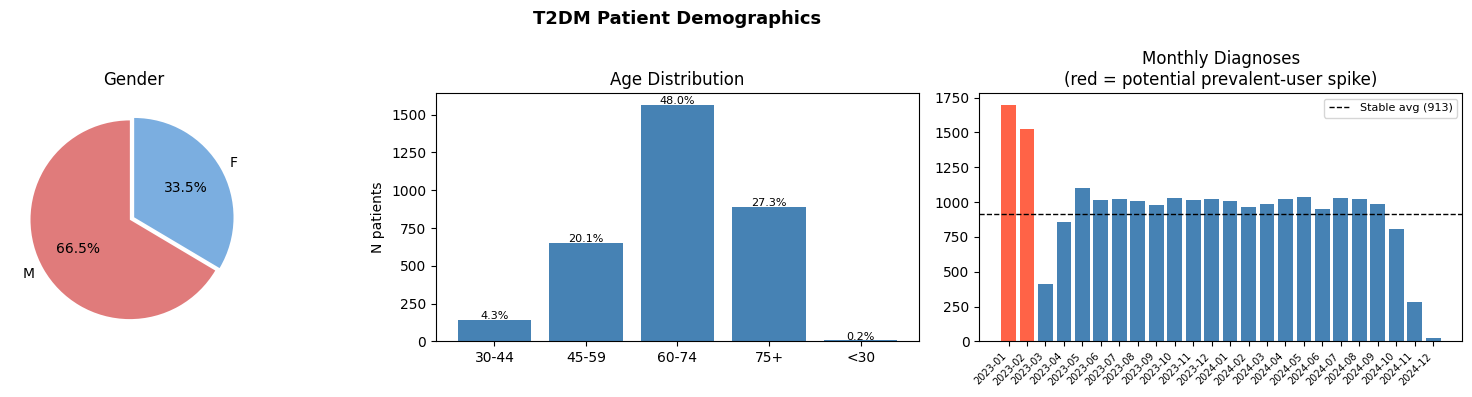

Total T2DM patients: 3,256
age_group    n
    30-44  141
    45-59  654
    60-74 1564
      75+  890
      <30    7


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
fig.suptitle('T2DM Patient Demographics', fontsize=13, fontweight='bold')

# Gender
df_gender = con.execute("""
    WITH t2 AS (
        SELECT DISTINCT co.person_id FROM main.condition_occurrence co
        JOIN main.concept c ON co.condition_concept_id = c.concept_id
        WHERE c.concept_name ILIKE '%type 2 diabetes mellitus%' AND c.standard_concept = 'S'
    )
    SELECT p.gender_source_value AS gender, COUNT(*) AS n
    FROM main.person p WHERE p.person_id IN (SELECT person_id FROM t2)
    GROUP BY 1 ORDER BY 2 DESC
""").df()
axes[0].pie(df_gender['n'], labels=df_gender['gender'], autopct='%1.1f%%',
            colors=['#e07b7b','#7baee0'], startangle=90, explode=[0.05,0])
axes[0].set_title('Gender')

# Age groups
df_age = con.execute("""
    WITH t2 AS (
        SELECT DISTINCT co.person_id FROM main.condition_occurrence co
        JOIN main.concept c ON co.condition_concept_id = c.concept_id
        WHERE c.concept_name ILIKE '%type 2 diabetes mellitus%' AND c.standard_concept = 'S'
    )
    SELECT CASE WHEN (2024-p.year_of_birth)<30  THEN '<30'
                WHEN (2024-p.year_of_birth)<45  THEN '30-44'
                WHEN (2024-p.year_of_birth)<60  THEN '45-59'
                WHEN (2024-p.year_of_birth)<75  THEN '60-74'
                ELSE '75+' END AS age_group,
           COUNT(*) AS n
    FROM main.person p WHERE p.person_id IN (SELECT person_id FROM t2)
    GROUP BY 1 ORDER BY 1
""").df()
bars = axes[1].bar(df_age['age_group'], df_age['n'], color='steelblue')
axes[1].set_title('Age Distribution')
axes[1].set_ylabel('N patients')
for bar, row in zip(bars, df_age.itertuples()):
    pct = row.n / df_age['n'].sum() * 100
    axes[1].text(bar.get_x()+bar.get_width()/2, bar.get_height()+5,
                 f'{pct:.1f}%', ha='center', fontsize=8)

# Temporal distribution
df_temp = con.execute("""
    WITH t2 AS (
        SELECT DISTINCT co.person_id,
               DATE_TRUNC('month', co.condition_start_date) AS month
        FROM main.condition_occurrence co
        JOIN main.concept c ON co.condition_concept_id = c.concept_id
        WHERE c.concept_name ILIKE '%type 2 diabetes mellitus%' AND c.standard_concept = 'S'
    )
    SELECT month, COUNT(*) AS n FROM t2 GROUP BY 1 ORDER BY 1
""").df()
colors_t = ['tomato' if str(m)[:7] in ('2023-01','2023-02') else 'steelblue'
            for m in df_temp['month']]
axes[2].bar(range(len(df_temp)), df_temp['n'], color=colors_t)
axes[2].set_xticks(range(len(df_temp)))
axes[2].set_xticklabels([str(m)[:7] for m in df_temp['month']], rotation=45, ha='right', fontsize=7)
axes[2].axhline(df_temp['n'][3:].mean(), color='black', linestyle='--', linewidth=1,
                label=f'Stable avg ({df_temp["n"][3:].mean():.0f})')
axes[2].set_title('Monthly Diagnoses\n(red = potential prevalent-user spike)')
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

print(f'Total T2DM patients: {n_t2dm:,}')
print(df_age.to_string(index=False))

## 2. Drug Enrichment Analysis
Which drugs are *specifically* associated with T2DM versus the general population?  
**Enrichment ratio** = % prescribed among T2DM patients ÷ % prescribed among all patients.  
A high ratio signals a drug disproportionately used in T2DM — no external drug list needed.

In [7]:

# Enrichment ratio: pct in T2DM ÷ pct in general population
# Drugs with high ratio are disproportionately prescribed to T2DM patients
n_all = con.execute("SELECT COUNT(DISTINCT person_id) FROM main.person").fetchone()[0]

df_enrichment = con.execute(f"""
    WITH t2 AS (
        SELECT DISTINCT co.person_id
        FROM main.condition_occurrence co
        JOIN main.concept c ON co.condition_concept_id = c.concept_id
        WHERE c.concept_name ILIKE '%type 2 diabetes mellitus%' AND c.standard_concept = 'S'
    ),
    pct_in_t2 AS (
        SELECT c.concept_name                                            AS drug,
               COUNT(DISTINCT de.person_id)                             AS n_t2,
               COUNT(DISTINCT de.person_id) * 100.0 / {n_t2dm}         AS pct_t2
        FROM main.drug_exposure de
        JOIN main.concept c ON de.drug_concept_id = c.concept_id
        WHERE de.person_id IN (SELECT person_id FROM t2)
          AND c.standard_concept = 'S' AND c.domain_id = 'Drug'
        GROUP BY c.concept_name
    ),
    pct_in_all AS (
        SELECT c.concept_name                                            AS drug,
               COUNT(DISTINCT de.person_id)                             AS n_all,
               COUNT(DISTINCT de.person_id) * 100.0 / {n_all}          AS pct_all
        FROM main.drug_exposure de
        JOIN main.concept c ON de.drug_concept_id = c.concept_id
        WHERE c.standard_concept = 'S' AND c.domain_id = 'Drug'
        GROUP BY c.concept_name
    )
    SELECT t.drug,
           t.n_t2,
           ROUND(t.pct_t2, 1)                           AS pct_t2dm,
           ROUND(a.pct_all, 1)                          AS pct_all_patients,
           ROUND(t.pct_t2 / NULLIF(a.pct_all, 0), 2)   AS enrichment_ratio
    FROM pct_in_t2 t
    JOIN pct_in_all a ON t.drug = a.drug
    ORDER BY enrichment_ratio DESC
""").df()

threshold = 3.0
n_enriched = (df_enrichment['enrichment_ratio'] >= threshold).sum()
print(f"Total drugs prescribed to T2DM patients : {len(df_enrichment)}")
print(f"Enrichment >= {threshold}x (T2DM-specific signal) : {n_enriched}")
print()
df_enrichment


Total drugs prescribed to T2DM patients : 186
Enrichment >= 3.0x (T2DM-specific signal) : 35



,drug,n_t2,pct_t2dm,pct_all_patients,enrichment_ratio
0,metformin,3223,99.00,32.20,3.07
1,Buformin,154,4.70,1.50,3.07
2,anagliptin,145,4.50,1.50,3.07
3,ipragliflozin,145,4.50,1.50,3.07
4,gliclazide,130,4.00,1.30,3.07
...,...,...,...,...,...
181,pemirolast,3,0.10,0.20,0.54
182,mebhydroline,3,0.10,0.20,0.48
183,tranilast,4,0.10,0.30,0.47
184,QUIFENADINE,2,0.10,0.20,0.41


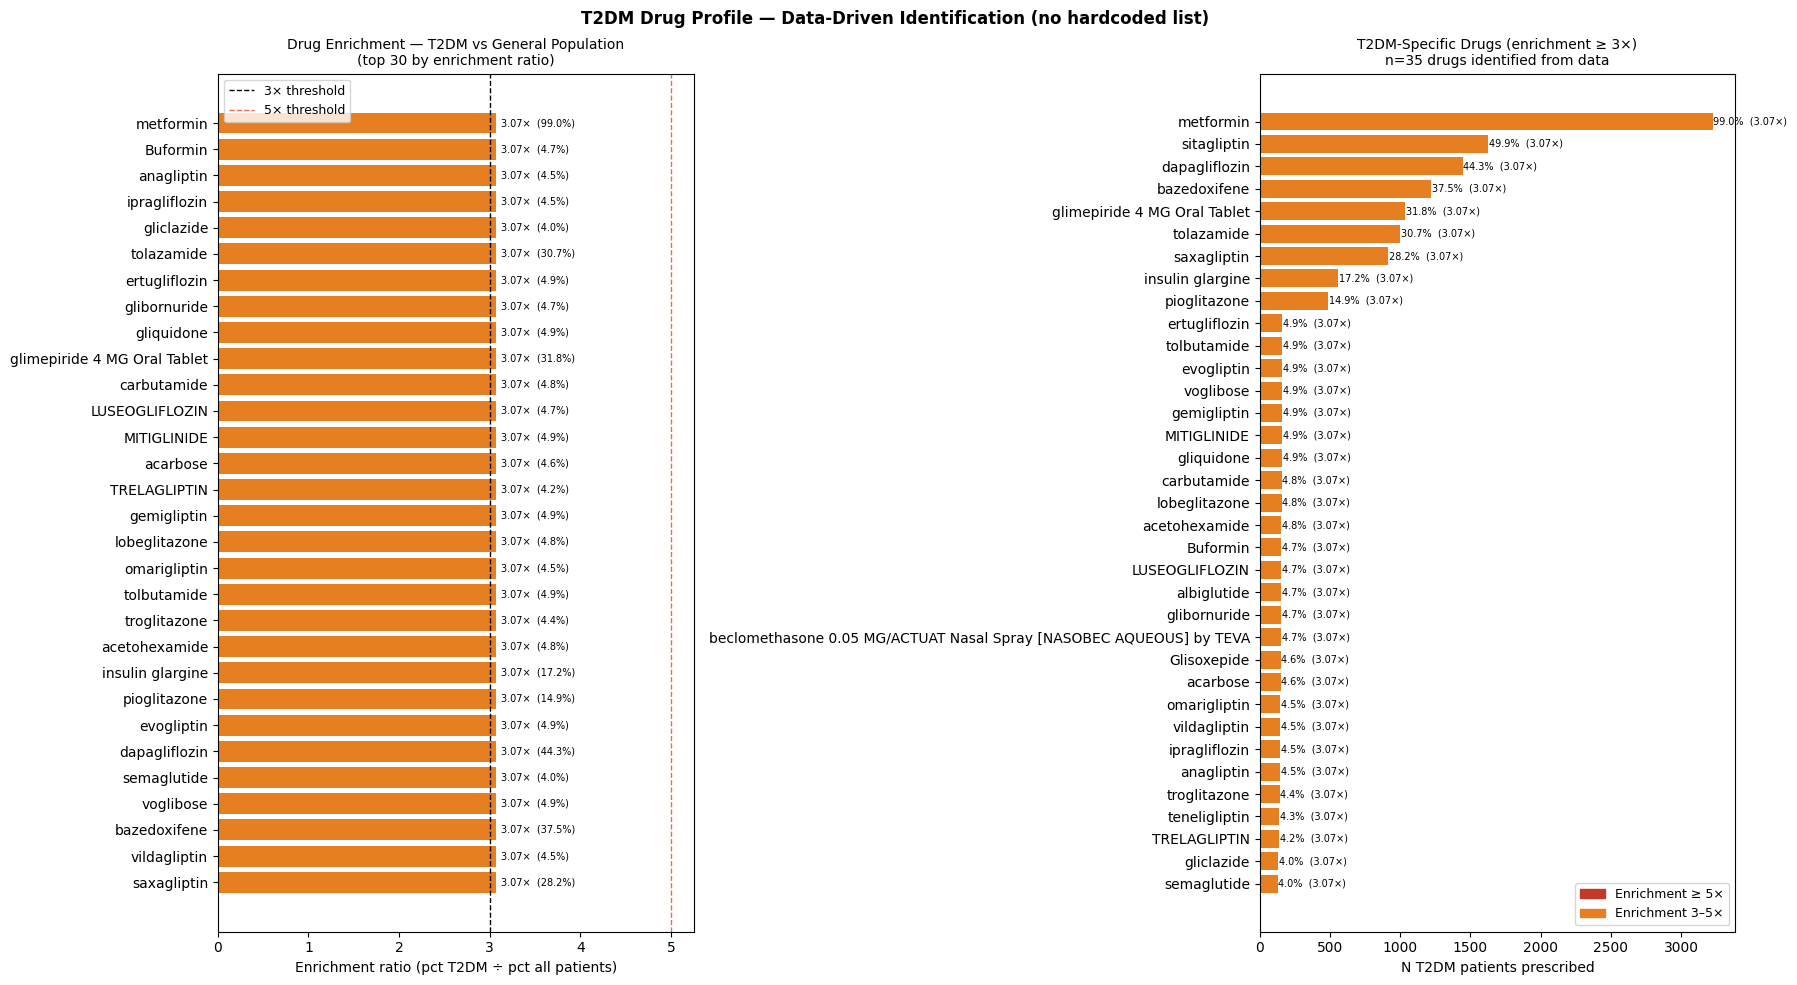

In [8]:

# Highlight T2DM-enriched drugs: top 30 by enrichment ratio
from matplotlib.patches import Patch

top_enriched = df_enrichment.head(30)

fig, axes = plt.subplots(1, 2, figsize=(18, 10))

# Left — enrichment ratio (log scale)
colors_enr = ['#c0392b' if r >= 5 else '#e67e22' if r >= 3 else '#3498db'
               for r in top_enriched['enrichment_ratio']]
axes[0].barh(top_enriched['drug'][::-1], top_enriched['enrichment_ratio'][::-1],
             color=colors_enr[::-1])
axes[0].axvline(3.0, color='black', linestyle='--', linewidth=1, label='3× threshold')
axes[0].axvline(5.0, color='tomato', linestyle='--', linewidth=1, label='5× threshold')
axes[0].set_xlabel('Enrichment ratio (pct T2DM ÷ pct all patients)')
axes[0].set_title('Drug Enrichment — T2DM vs General Population\n(top 30 by enrichment ratio)', fontsize=10)
axes[0].legend(fontsize=9)
for i, (_, row) in enumerate(top_enriched[::-1].reset_index().iterrows()):
    axes[0].text(row['enrichment_ratio'] + 0.05, i,
                 f"{row['enrichment_ratio']}×  ({row['pct_t2dm']}%)", va='center', fontsize=7)

# Right — patient count for enriched drugs only (≥ 3×)
enriched = df_enrichment[df_enrichment['enrichment_ratio'] >= 3.0].sort_values('n_t2')
colors_n = ['#c0392b' if r >= 5 else '#e67e22' for r in enriched['enrichment_ratio']]
axes[1].barh(enriched['drug'], enriched['n_t2'], color=colors_n)
axes[1].set_xlabel('N T2DM patients prescribed')
axes[1].set_title(f'T2DM-Specific Drugs (enrichment ≥ 3×)\nn={len(enriched)} drugs identified from data', fontsize=10)
for i, (_, row) in enumerate(enriched.iterrows()):
    axes[1].text(row['n_t2'] + 5, i,
                 f"{row['pct_t2dm']}%  ({row['enrichment_ratio']}×)", va='center', fontsize=7)

axes[1].legend(handles=[
    Patch(color='#c0392b', label='Enrichment ≥ 5×'),
    Patch(color='#e67e22', label='Enrichment 3–5×'),
], fontsize=9)

plt.suptitle('T2DM Drug Profile — Data-Driven Identification (no hardcoded list)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('t2dm_drug_enrichment.png', dpi=150, bbox_inches='tight')
plt.show()


## 3. Complete Drug List
All drugs prescribed to T2DM patients (antidiabetics + co-medications).

In [9]:
df_all_drugs_t2 = con.execute("""
    WITH t2 AS (
        SELECT DISTINCT co.person_id FROM main.condition_occurrence co
        JOIN main.concept c ON co.condition_concept_id = c.concept_id
        WHERE c.concept_name ILIKE '%type 2 diabetes mellitus%' AND c.standard_concept = 'S'
    )
    SELECT c.concept_name AS drug,
           c.concept_class_id AS drug_class,
           c.vocabulary_id    AS vocabulary,
           COUNT(DISTINCT de.person_id) AS n_patients,
           COUNT(*)                      AS n_prescriptions,
           ROUND(COUNT(DISTINCT de.person_id)*100.0/(SELECT COUNT(*) FROM t2),1) AS pct
    FROM main.drug_exposure de
    JOIN main.concept c ON de.drug_concept_id = c.concept_id
    WHERE de.person_id IN (SELECT person_id FROM t2)
      AND c.standard_concept = 'S' AND c.domain_id = 'Drug'
    GROUP BY 1,2,3 ORDER BY n_patients DESC
""").df()

print(f'Total distinct drugs: {len(df_all_drugs_t2)}')
df_all_drugs_t2

Total distinct drugs: 186


,drug,drug_class,vocabulary,n_patients,n_prescriptions,pct
0,metformin,Ingredient,RxNorm,3223,14817,99.00
1,atorvastatin,Ingredient,RxNorm,2431,4751,74.70
2,acetaminophen,Ingredient,RxNorm,2412,6243,74.10
3,rosuvastatin,Ingredient,RxNorm,2194,3771,67.40
4,amlodipine,Ingredient,RxNorm,2166,6557,66.50
...,...,...,...,...,...,...
181,mebhydroline,Ingredient,RxNorm,3,3,0.10
182,QUIFENADINE,Ingredient,RxNorm Extension,2,2,0.10
183,clobetasol propionate 0.5 MG/ML Topical Foam,Clinical Drug,RxNorm,2,2,0.10
184,amcinonide,Ingredient,RxNorm,1,1,0.00


## 4. All Possible Treatment Combinations — Feasibility Matrix
For every pair of T2DM-enriched drugs (enrichment ≥ 3×, n ≥ 100 patients), compute balance and positivity.  
This gives a complete, data-driven view of all candidate comparisons — no pre-selection.

In [10]:

import itertools
import numpy as np

# Keep only enriched drugs with enough patients for meaningful comparison
MIN_PATIENTS = 100

if 'n_t2dm' not in globals():
    n_t2dm = con.execute("""
        SELECT COUNT(DISTINCT co.person_id)
        FROM main.condition_occurrence co
        JOIN main.concept c ON co.condition_concept_id = c.concept_id
        WHERE c.concept_name ILIKE '%type 2 diabetes mellitus%' AND c.standard_concept = 'S'
    """).fetchone()[0]

if 'df_enrichment' not in globals():
    n_all = con.execute("SELECT COUNT(DISTINCT person_id) FROM main.person").fetchone()[0]
    df_enrichment = con.execute(f"""
        WITH t2 AS (
            SELECT DISTINCT co.person_id
            FROM main.condition_occurrence co
            JOIN main.concept c ON co.condition_concept_id = c.concept_id
            WHERE c.concept_name ILIKE '%type 2 diabetes mellitus%' AND c.standard_concept = 'S'
        ),
        pct_in_t2 AS (
            SELECT c.concept_name AS drug,
                   COUNT(DISTINCT de.person_id) AS n_t2,
                   COUNT(DISTINCT de.person_id) * 100.0 / {n_t2dm} AS pct_t2
            FROM main.drug_exposure de
            JOIN main.concept c ON de.drug_concept_id = c.concept_id
            WHERE de.person_id IN (SELECT person_id FROM t2)
              AND c.standard_concept = 'S' AND c.domain_id = 'Drug'
            GROUP BY c.concept_name
        ),
        pct_in_all AS (
            SELECT c.concept_name AS drug,
                   COUNT(DISTINCT de.person_id) AS n_all,
                   COUNT(DISTINCT de.person_id) * 100.0 / {n_all} AS pct_all
            FROM main.drug_exposure de
            JOIN main.concept c ON de.drug_concept_id = c.concept_id
            WHERE c.standard_concept = 'S' AND c.domain_id = 'Drug'
            GROUP BY c.concept_name
        )
        SELECT t.drug,
               t.n_t2,
               ROUND(t.pct_t2, 1) AS pct_t2dm,
               ROUND(a.pct_all, 1) AS pct_all_patients,
               ROUND(t.pct_t2 / NULLIF(a.pct_all, 0), 2) AS enrichment_ratio
        FROM pct_in_t2 t
        JOIN pct_in_all a ON t.drug = a.drug
        ORDER BY enrichment_ratio DESC
    """).df()
candidates = df_enrichment[
    (df_enrichment['enrichment_ratio'] >= 3.0) &
    (df_enrichment['n_t2'] >= MIN_PATIENTS)
]['drug'].tolist()

print(f"Candidate drugs (enrichment ≥ 3×, n ≥ {MIN_PATIENTS}): {len(candidates)}")
for d in candidates:
    row = df_enrichment[df_enrichment['drug'] == d].iloc[0]
    print(f"  {d:<40} n={row['n_t2']:>5}  enr={row['enrichment_ratio']}×")

# Compute all pairs
pairs = list(itertools.combinations(candidates, 2))
print(f"\nTotal pairs to evaluate: {len(pairs)}")

rows = []
for drug_a, drug_b in pairs:
    n_a = con.execute(f"""
        WITH t2 AS (SELECT DISTINCT co.person_id FROM main.condition_occurrence co
            JOIN main.concept c ON co.condition_concept_id = c.concept_id
            WHERE c.concept_name ILIKE '%type 2 diabetes mellitus%' AND c.standard_concept = 'S')
        SELECT COUNT(DISTINCT de.person_id) FROM main.drug_exposure de
        JOIN main.concept c ON de.drug_concept_id = c.concept_id
        WHERE de.person_id IN (SELECT person_id FROM t2)
          AND c.concept_name = '{drug_a}' AND c.standard_concept = 'S'
    """).fetchone()[0]
    n_b = con.execute(f"""
        WITH t2 AS (SELECT DISTINCT co.person_id FROM main.condition_occurrence co
            JOIN main.concept c ON co.condition_concept_id = c.concept_id
            WHERE c.concept_name ILIKE '%type 2 diabetes mellitus%' AND c.standard_concept = 'S')
        SELECT COUNT(DISTINCT de.person_id) FROM main.drug_exposure de
        JOIN main.concept c ON de.drug_concept_id = c.concept_id
        WHERE de.person_id IN (SELECT person_id FROM t2)
          AND c.concept_name = '{drug_b}' AND c.standard_concept = 'S'
    """).fetchone()[0]
    total = n_a + n_b
    pct_a = n_a / total * 100 if total > 0 else 0
    balance = min(pct_a, 100 - pct_a)  # 50 = perfect, 0 = worst
    feasible = 10 <= pct_a <= 90
    rows.append({'drug_A': drug_a, 'drug_B': drug_b,
                 'n_A': n_a, 'n_B': n_b,
                 'pct_A': round(pct_a, 1),
                 'balance_score': round(balance, 1),
                 'feasible': feasible})

df_pairs = pd.DataFrame(rows).sort_values('balance_score', ascending=False)
print(f"\nFeasible pairs (positivity OK): {df_pairs['feasible'].sum()} / {len(df_pairs)}")
df_pairs


Candidate drugs (enrichment ≥ 3×, n ≥ 100): 35
  metformin                                n= 3223  enr=3.07×
  Buformin                                 n=  154  enr=3.07×
  anagliptin                               n=  145  enr=3.07×
  ipragliflozin                            n=  145  enr=3.07×
  gliclazide                               n=  130  enr=3.07×
  tolazamide                               n= 1000  enr=3.07×
  ertugliflozin                            n=  160  enr=3.07×
  glibornuride                             n=  153  enr=3.07×
  gliquidone                               n=  158  enr=3.07×
  glimepiride 4 MG Oral Tablet             n= 1034  enr=3.07×
  carbutamide                              n=  157  enr=3.07×
  LUSEOGLIFLOZIN                           n=  154  enr=3.07×
  MITIGLINIDE                              n=  158  enr=3.07×
  acarbose                                 n=  149  enr=3.07×
  TRELAGLIPTIN                             n=  138  enr=3.07×
  gemigliptin          

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


Feasible pairs (positivity OK): 515 / 595


,drug_A,drug_B,n_A,n_B,pct_A,balance_score,feasible
261,gliquidone,voglibose,158,158,50.00,50.00,True
43,Buformin,LUSEOGLIFLOZIN,154,154,50.00,50.00,True
355,MITIGLINIDE,voglibose,158,158,50.00,50.00,True
67,anagliptin,ipragliflozin,145,145,50.00,50.00,True
341,LUSEOGLIFLOZIN,albiglutide,154,154,50.00,50.00,True
...,...,...,...,...,...,...,...
32,metformin,teneligliptin,3223,140,95.80,4.20,False
18,metformin,troglitazone,3223,142,95.80,4.20,False
13,metformin,TRELAGLIPTIN,3223,138,95.90,4.10,False
3,metformin,gliclazide,3223,130,96.10,3.90,False


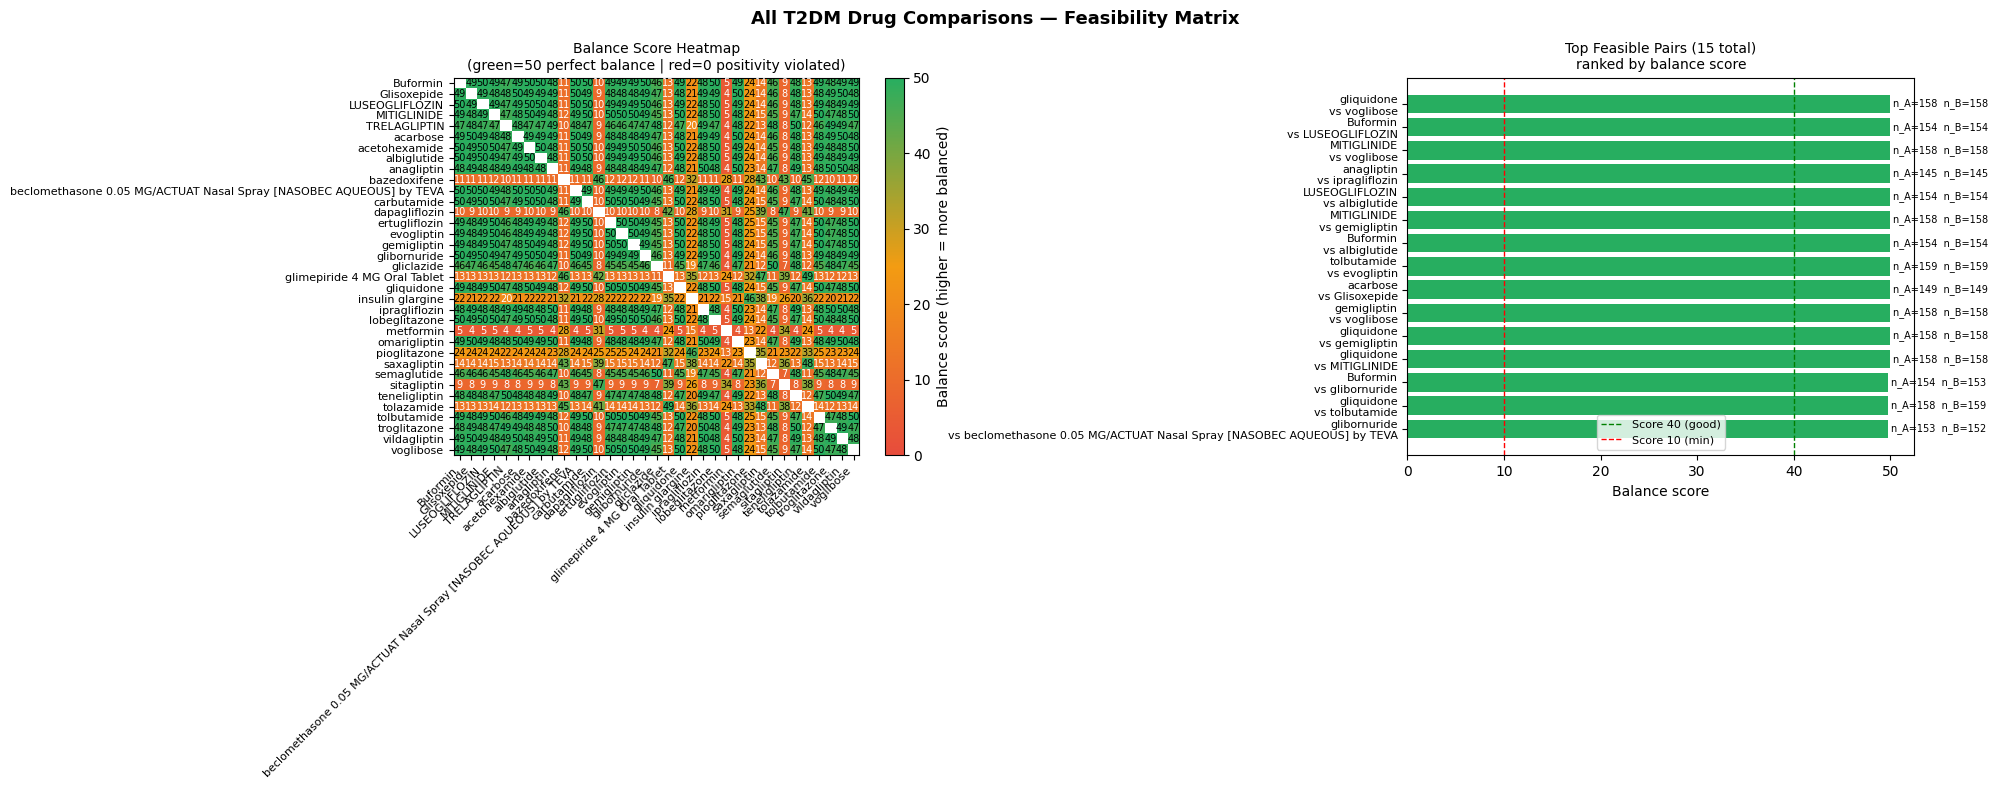

In [11]:
import numpy as np
import itertools


# Heatmap: balance score for all drug pairs
# balance_score = min(pct_A, pct_B) — 50 = perfect balance, <10 = positivity violation
if 'df_pairs' not in globals():
    if 'df_enrichment' not in globals():
        n_all = con.execute("SELECT COUNT(DISTINCT person_id) FROM main.person").fetchone()[0]
        df_enrichment = con.execute(f"""
            WITH t2 AS (
                SELECT DISTINCT co.person_id
                FROM main.condition_occurrence co
                JOIN main.concept c ON co.condition_concept_id = c.concept_id
                WHERE c.concept_name ILIKE '%type 2 diabetes mellitus%' AND c.standard_concept = 'S'
            ),
            pct_in_t2 AS (
                SELECT c.concept_name AS drug,
                       COUNT(DISTINCT de.person_id) AS n_t2,
                       COUNT(DISTINCT de.person_id) * 100.0 / {n_t2dm} AS pct_t2
                FROM main.drug_exposure de
                JOIN main.concept c ON de.drug_concept_id = c.concept_id
                WHERE de.person_id IN (SELECT person_id FROM t2)
                  AND c.standard_concept = 'S' AND c.domain_id = 'Drug'
                GROUP BY c.concept_name
            ),
            pct_in_all AS (
                SELECT c.concept_name AS drug,
                       COUNT(DISTINCT de.person_id) AS n_all,
                       COUNT(DISTINCT de.person_id) * 100.0 / {n_all} AS pct_all
                FROM main.drug_exposure de
                JOIN main.concept c ON de.drug_concept_id = c.concept_id
                WHERE c.standard_concept = 'S' AND c.domain_id = 'Drug'
                GROUP BY c.concept_name
            )
            SELECT t.drug,
                   t.n_t2,
                   ROUND(t.pct_t2, 1) AS pct_t2dm,
                   ROUND(a.pct_all, 1) AS pct_all_patients,
                   ROUND(t.pct_t2 / NULLIF(a.pct_all, 0), 2) AS enrichment_ratio
            FROM pct_in_t2 t
            JOIN pct_in_all a ON t.drug = a.drug
            ORDER BY enrichment_ratio DESC
        """).df()

    drug_counts = df_enrichment.set_index('drug')['n_t2'].to_dict()
    candidates = df_enrichment[
        (df_enrichment['enrichment_ratio'] >= 3.0) &
        (df_enrichment['n_t2'] >= MIN_PATIENTS)
    ]['drug'].tolist()

    rows = []
    for drug_a, drug_b in itertools.combinations(candidates, 2):
        n_a = int(drug_counts[drug_a])
        n_b = int(drug_counts[drug_b])
        total = n_a + n_b
        pct_a = n_a / total * 100 if total > 0 else 0
        rows.append({
            'drug_A': drug_a,
            'drug_B': drug_b,
            'n_A': n_a,
            'n_B': n_b,
            'pct_A': round(pct_a, 1),
            'balance_score': round(min(pct_a, 100 - pct_a), 1),
            'feasible': 10 <= pct_a <= 90
        })

    df_pairs = pd.DataFrame(rows).sort_values('balance_score', ascending=False)
pivot = df_pairs.pivot_table(index='drug_A', columns='drug_B', values='balance_score')

# Fill symmetric values
for _, row in df_pairs.iterrows():
    if row['drug_A'] not in pivot.columns:
        pivot[row['drug_A']] = np.nan
    if row['drug_B'] not in pivot.index:
        pivot.loc[row['drug_B']] = np.nan
    pivot.loc[row['drug_A'], row['drug_B']] = row['balance_score']
    pivot.loc[row['drug_B'], row['drug_A']] = row['balance_score']

all_drugs = sorted(set(df_pairs['drug_A'].tolist() + df_pairs['drug_B'].tolist()))
pivot = pivot.reindex(index=all_drugs, columns=all_drugs)

fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# Heatmap
import matplotlib.colors as mcolors
cmap = mcolors.LinearSegmentedColormap.from_list('', ['#e74c3c', '#f39c12', '#27ae60'])
im = axes[0].imshow(pivot.values.astype(float), cmap=cmap, vmin=0, vmax=50, aspect='auto')
axes[0].set_xticks(range(len(all_drugs)))
axes[0].set_yticks(range(len(all_drugs)))
axes[0].set_xticklabels(all_drugs, rotation=45, ha='right', fontsize=8)
axes[0].set_yticklabels(all_drugs, fontsize=8)
axes[0].set_title('Balance Score Heatmap\n(green=50 perfect balance | red=0 positivity violated)', fontsize=10)
plt.colorbar(im, ax=axes[0], label='Balance score (higher = more balanced)')

for i in range(len(all_drugs)):
    for j in range(len(all_drugs)):
        val = pivot.values[i, j]
        if not np.isnan(val):
            txt = f"{val:.0f}"
            color = 'white' if val < 20 else 'black'
            axes[0].text(j, i, txt, ha='center', va='center', fontsize=7, color=color)

# Bar chart: top feasible pairs by balance score
feasible_pairs = df_pairs[df_pairs['feasible']].head(15)
labels = [f"{r['drug_A']}\nvs {r['drug_B']}" for _, r in feasible_pairs.iterrows()]
colors_bar = ['#27ae60' if s >= 40 else '#f39c12' if s >= 25 else '#e67e22'
               for s in feasible_pairs['balance_score']]
axes[1].barh(range(len(feasible_pairs)), feasible_pairs['balance_score'][::-1].values,
             color=colors_bar[::-1])
axes[1].set_yticks(range(len(feasible_pairs)))
axes[1].set_yticklabels(labels[::-1], fontsize=8)
axes[1].axvline(40, color='green', linestyle='--', linewidth=1, label='Score 40 (good)')
axes[1].axvline(10, color='red',   linestyle='--', linewidth=1, label='Score 10 (min)')
axes[1].set_xlabel('Balance score')
axes[1].set_title(f'Top Feasible Pairs ({feasible_pairs["feasible"].sum()} total)\nranked by balance score', fontsize=10)
axes[1].legend(fontsize=8)

for i, (_, row) in enumerate(feasible_pairs[::-1].reset_index().iterrows()):
    axes[1].text(row['balance_score'] + 0.3, i,
                 f"n_A={row['n_A']:,}  n_B={row['n_B']:,}", va='center', fontsize=7)

plt.suptitle('All T2DM Drug Comparisons — Feasibility Matrix', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('t2dm_comparison_matrix.png', dpi=150, bbox_inches='tight')
plt.show()


## 5. Treatment Changes per Patient

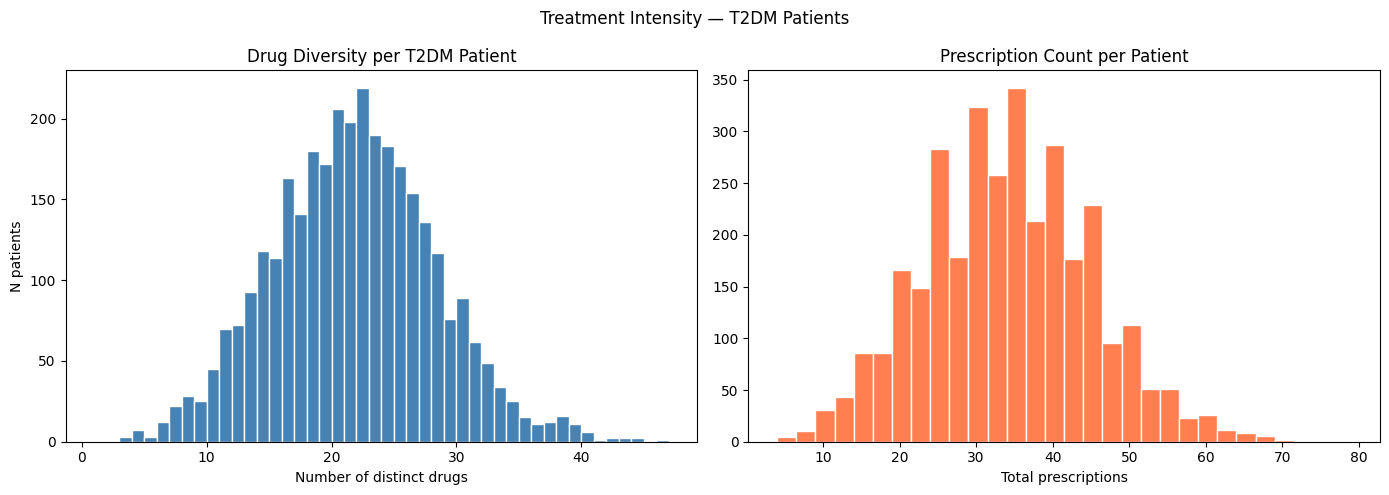

Avg distinct drugs : 21.3
Median            : 21
Max               : 46

Top 10 patients — most distinct drugs:


,person_id,n_distinct_drugs,n_prescriptions,first_rx,last_rx
0,702,46,70,2023-01-01,2024-12-08
1,9890,44,68,2023-01-03,2024-12-09
2,4168,44,69,2023-01-08,2024-11-18
3,7590,43,79,2023-01-11,2024-12-02
4,9479,43,57,2023-01-12,2024-12-01
5,4731,42,62,2023-01-07,2024-10-23
6,545,42,65,2023-01-04,2024-10-21
7,4236,41,60,2023-01-14,2024-12-20
8,6984,40,68,2023-01-03,2024-11-14
9,3747,40,56,2023-01-06,2024-11-26


In [12]:
df_tx_changes = con.execute("""
    WITH t2 AS (
        SELECT DISTINCT co.person_id FROM main.condition_occurrence co
        JOIN main.concept c ON co.condition_concept_id = c.concept_id
        WHERE c.concept_name ILIKE '%type 2 diabetes mellitus%' AND c.standard_concept = 'S'
    )
    SELECT de.person_id,
           COUNT(DISTINCT de.drug_concept_id) AS n_distinct_drugs,
           COUNT(*)                            AS n_prescriptions,
           MIN(de.drug_exposure_start_date)    AS first_rx,
           MAX(de.drug_exposure_start_date)    AS last_rx
    FROM main.drug_exposure de
    WHERE de.person_id IN (SELECT person_id FROM t2) AND de.drug_concept_id != 0
    GROUP BY de.person_id
""").df()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(df_tx_changes['n_distinct_drugs'],
             bins=range(1, df_tx_changes['n_distinct_drugs'].max()+2),
             color='steelblue', edgecolor='white')
axes[0].set_xlabel('Number of distinct drugs')
axes[0].set_ylabel('N patients')
axes[0].set_title('Drug Diversity per T2DM Patient')

axes[1].hist(df_tx_changes['n_prescriptions'], bins=30, color='coral', edgecolor='white')
axes[1].set_xlabel('Total prescriptions')
axes[1].set_title('Prescription Count per Patient')

plt.suptitle('Treatment Intensity — T2DM Patients', fontsize=12)
plt.tight_layout()
plt.show()

print(f"Avg distinct drugs : {df_tx_changes['n_distinct_drugs'].mean():.1f}")
print(f"Median            : {df_tx_changes['n_distinct_drugs'].median():.0f}")
print(f"Max               : {df_tx_changes['n_distinct_drugs'].max()}")
print()
print('Top 10 patients — most distinct drugs:')
df_tx_changes.sort_values('n_distinct_drugs', ascending=False).head(10).reset_index(drop=True)

## 6. Measurements as Outcomes
HbA1c, fasting glucose, LDL and systolic BP — available as continuous outcome variables.

In [ ]:
# ── Complete measurement inventory for T2DM patients ──────────────────────────
# Sources: measurement table (lab results + BP) + observation table (vital signs)

# 1. From measurement table
df_meas_lab = con.execute("""
    WITH t2 AS (
        SELECT DISTINCT co.person_id FROM main.condition_occurrence co
        JOIN main.concept c ON co.condition_concept_id = c.concept_id
        WHERE c.concept_name ILIKE '%type 2 diabetes mellitus%' AND c.standard_concept = 'S'
    )
    SELECT c.concept_name AS measurement, c.concept_code AS loinc_code,
           'measurement' AS source_table,
           COUNT(*) AS n_records,
           COUNT(DISTINCT m.person_id) AS n_patients,
           ROUND(COUNT(DISTINCT m.person_id)*100.0/(SELECT COUNT(*) FROM t2),1) AS pct_t2dm,
           ROUND(AVG(m.value_as_number),2) AS mean_val,
           ROUND(MIN(m.value_as_number),2) AS min_val,
           ROUND(MAX(m.value_as_number),2) AS max_val,
           m.unit_source_value AS unit
    FROM main.measurement m
    JOIN main.concept c ON m.measurement_concept_id = c.concept_id
    WHERE m.person_id IN (SELECT person_id FROM t2) AND m.measurement_concept_id != 0
    GROUP BY 1,2,3,10 ORDER BY n_records DESC
""").df()

# 2. Vital signs from observation table (LOINC-coded, numeric)
df_obs_vital = con.execute("""
    WITH t2 AS (
        SELECT DISTINCT co.person_id FROM main.condition_occurrence co
        JOIN main.concept c ON co.condition_concept_id = c.concept_id
        WHERE c.concept_name ILIKE '%type 2 diabetes mellitus%' AND c.standard_concept = 'S'
    )
    SELECT c.concept_name AS measurement, c.concept_code AS loinc_code,
           'observation (vital signs)' AS source_table,
           COUNT(*) AS n_records,
           COUNT(DISTINCT o.person_id) AS n_patients,
           ROUND(COUNT(DISTINCT o.person_id)*100.0/(SELECT COUNT(*) FROM t2),1) AS pct_t2dm,
           ROUND(AVG(o.value_as_number),2) AS mean_val,
           ROUND(MIN(o.value_as_number),2) AS min_val,
           ROUND(MAX(o.value_as_number),2) AS max_val,
           o.unit_source_value AS unit
    FROM main.observation o
    JOIN main.concept c ON o.observation_concept_id = c.concept_id
    WHERE o.person_id IN (SELECT person_id FROM t2)
      AND c.vocabulary_id = 'LOINC' AND o.value_as_number IS NOT NULL
    GROUP BY 1,2,3,10 ORDER BY n_records DESC
""").df()

# Assign categories
def categorise(name):
    n = name.lower()
    if any(k in n for k in ['glucose','hemoglobin a1c','hba1c']): return 'Glycemic'
    if any(k in n for k in ['cholesterol','triglyceride','ldl','hdl']): return 'Lipids'
    if 'blood pressure' in n: return 'Blood pressure'
    if any(k in n for k in ['heart rate','temperature','oxygen','respiratory']): return 'Vital signs'
    return 'Other'

df_meas_lab['category'] = df_meas_lab['measurement'].map(categorise)
df_obs_vital['category'] = df_obs_vital['measurement'].map(categorise)

import pandas as pd
cols = ['measurement','loinc_code','source_table','category',
        'n_records','n_patients','pct_t2dm','mean_val','min_val','max_val','unit']
df_all_meas = pd.concat([df_meas_lab[cols], df_obs_vital[cols]], ignore_index=True)

bmi_present = any(df_all_meas['measurement'].str.contains('bmi|body mass', case=False))
print(f"BMI available in dataset : {bmi_present}  ← explicit limitation")
print(f"Total distinct measurement types : {len(df_all_meas)}")
print()
df_all_meas


In [ ]:
# ── Visualisation: coverage + value range ─────────────────────────────────────
import matplotlib.patches as mpatches

category_colors = {
    'Glycemic':       '#27ae60',
    'Lipids':          '#2980b9',
    'Blood pressure':  '#8e44ad',
    'Vital signs':     '#e67e22',
    'Other':           '#95a5a6',
}

df_plot = df_all_meas.sort_values('pct_t2dm', ascending=True)
colors  = [category_colors.get(c, '#95a5a6') for c in df_plot['category']]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Measurement Inventory — T2DM Patients (n=3,256)', fontsize=13, fontweight='bold')

# Left: coverage
bars = axes[0].barh(df_plot['measurement'], df_plot['pct_t2dm'], color=colors)
axes[0].set_xlabel('% T2DM patients with ≥1 record')
axes[0].set_title('Coverage by Measurement Type')
axes[0].axvline(50, color='gray', linestyle='--', linewidth=1, alpha=0.5)
for bar, (_, row) in zip(bars, df_plot.iterrows()):
    axes[0].text(row['pct_t2dm']+0.5, bar.get_y()+bar.get_height()/2,
                 f"{row['pct_t2dm']}%  (n={row['n_patients']:,})",
                 va='center', fontsize=8)
legend_patches = [mpatches.Patch(color=v, label=k) for k,v in category_colors.items()]
axes[0].legend(handles=legend_patches, fontsize=8, loc='lower right')

# Right: mean + range
df_num = df_plot[df_plot['mean_val'].notna()].copy()
colors2 = [category_colors.get(c, '#95a5a6') for c in df_num['category']]
y = range(len(df_num))
axes[1].barh(list(y), df_num['max_val'] - df_num['min_val'],
             left=df_num['min_val'].values, color=colors2, alpha=0.3)
axes[1].scatter(df_num['mean_val'].values, list(y), color=colors2, zorder=5, s=60)
axes[1].set_yticks(list(y))
axes[1].set_yticklabels(
    [f"{row['measurement'][:35]} ({row['unit']})" for _, row in df_num.iterrows()],
    fontsize=8)
axes[1].set_xlabel('Value range (bar) + mean (dot)')
axes[1].set_title('Distribution of Measurement Values')

fig.text(0.5, -0.03,
         '⚠  BMI not available in this dataset — explicit limitation for causal analysis',
         ha='center', fontsize=10, color='tomato', fontweight='bold')

plt.tight_layout()
plt.savefig('t2dm_measurement_inventory.png', dpi=150, bbox_inches='tight')
plt.show()


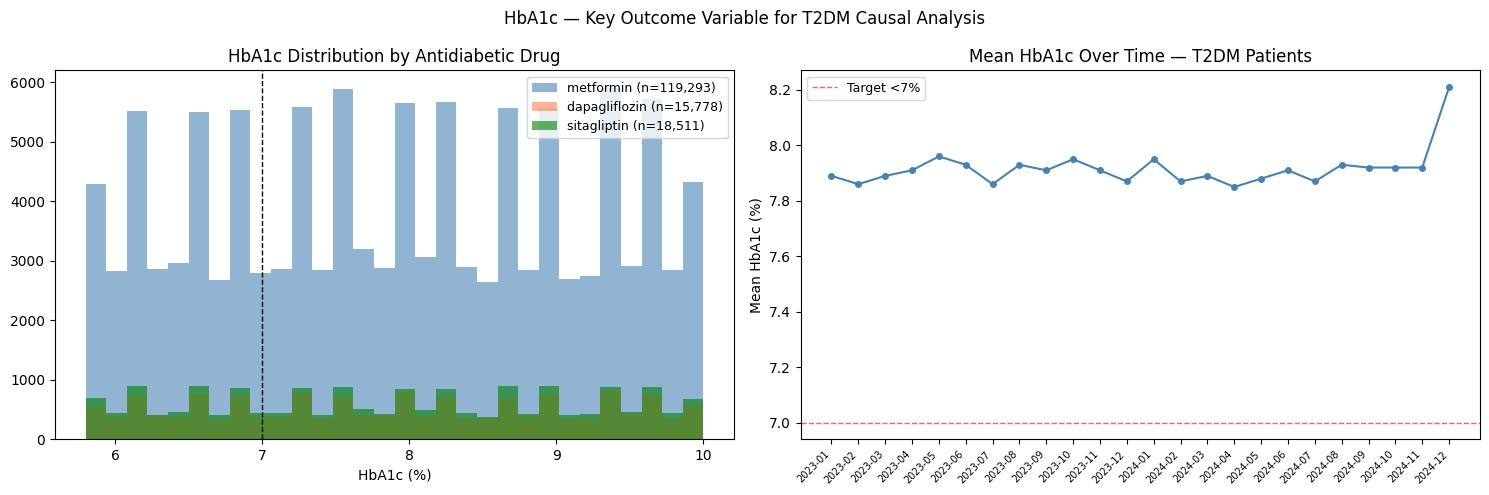

In [14]:
# HbA1c distribution: metformin vs dapagliflozin vs sitagliptin
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# HbA1c by antidiabetic
for drug, color in [('metformin','steelblue'), ('dapagliflozin','coral'), ('sitagliptin','green')]:
    vals = con.execute(f"""
        SELECT m.value_as_number
        FROM main.measurement m
        JOIN main.concept cm ON m.measurement_concept_id = cm.concept_id
        JOIN main.drug_exposure de ON m.person_id = de.person_id
        JOIN main.concept cd ON de.drug_concept_id = cd.concept_id
        WHERE cm.concept_code = '4548-4'
          AND cd.concept_name ILIKE '%{drug}%' AND cd.standard_concept = 'S'
          AND m.value_as_number BETWEEN 4 AND 15
    """).df()['value_as_number']
    axes[0].hist(vals, bins=30, alpha=0.6, label=f'{drug} (n={len(vals):,})', color=color)
axes[0].set_xlabel('HbA1c (%)')
axes[0].set_title('HbA1c Distribution by Antidiabetic Drug')
axes[0].legend(fontsize=9)
axes[0].axvline(7.0, color='black', linestyle='--', linewidth=1, label='Target <7%')

# HbA1c over time (all T2DM)
df_hba1c_time = con.execute("""
    WITH t2 AS (
        SELECT DISTINCT co.person_id FROM main.condition_occurrence co
        JOIN main.concept c ON co.condition_concept_id = c.concept_id
        WHERE c.concept_name ILIKE '%type 2 diabetes mellitus%' AND c.standard_concept = 'S'
    )
    SELECT DATE_TRUNC('month', m.measurement_date) AS month,
           ROUND(AVG(m.value_as_number), 2) AS mean_hba1c,
           COUNT(*) AS n
    FROM main.measurement m
    JOIN main.concept cm ON m.measurement_concept_id = cm.concept_id
    WHERE m.person_id IN (SELECT person_id FROM t2)
      AND cm.concept_code = '4548-4'
      AND m.value_as_number BETWEEN 4 AND 15
    GROUP BY 1 ORDER BY 1
""").df()
axes[1].plot(range(len(df_hba1c_time)), df_hba1c_time['mean_hba1c'],
             color='steelblue', marker='o', markersize=4)
axes[1].set_xticks(range(len(df_hba1c_time)))
axes[1].set_xticklabels([str(m)[:7] for m in df_hba1c_time['month']],
                         rotation=45, ha='right', fontsize=7)
axes[1].axhline(7.0, color='tomato', linestyle='--', linewidth=1, label='Target <7%')
axes[1].set_ylabel('Mean HbA1c (%)')
axes[1].set_title('Mean HbA1c Over Time — T2DM Patients')
axes[1].legend(fontsize=9)

plt.suptitle('HbA1c — Key Outcome Variable for T2DM Causal Analysis', fontsize=12)
plt.tight_layout()
plt.savefig('t2dm_hba1c.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Adverse Events Signal
New conditions appearing within 90 days after antidiabetic initiation — empirical side-effect signal.

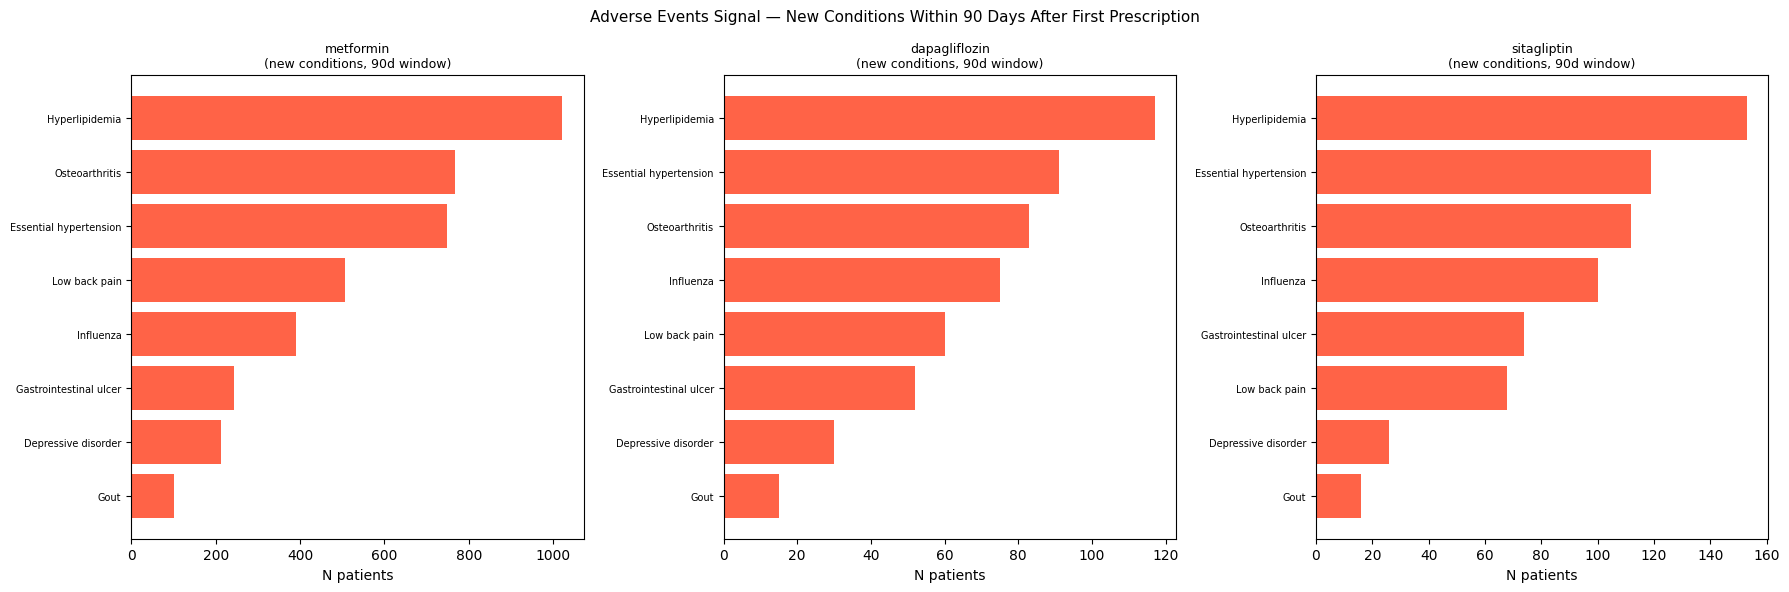

In [15]:
def get_new_conditions_t2(drug_name, days=90, top_n=10):
    return con.execute(f"""
        WITH t2 AS (
            SELECT DISTINCT co.person_id FROM main.condition_occurrence co
            JOIN main.concept c ON co.condition_concept_id = c.concept_id
            WHERE c.concept_name ILIKE '%type 2 diabetes mellitus%' AND c.standard_concept = 'S'
        ),
        drug_starts AS (
            SELECT de.person_id, MIN(de.drug_exposure_start_date) AS drug_start
            FROM main.drug_exposure de
            JOIN main.concept c ON de.drug_concept_id = c.concept_id
            WHERE c.concept_name ILIKE '%{drug_name}%' AND c.standard_concept = 'S'
              AND de.person_id IN (SELECT person_id FROM t2)
            GROUP BY de.person_id
        ),
        new_conds AS (
            SELECT DISTINCT co.person_id, co.condition_concept_id
            FROM main.condition_occurrence co
            JOIN drug_starts ds ON co.person_id = ds.person_id
            WHERE co.condition_start_date >  ds.drug_start
              AND co.condition_start_date <= ds.drug_start + INTERVAL '{days} days'
              AND NOT EXISTS (
                  SELECT 1 FROM main.condition_occurrence co2
                  WHERE co2.person_id = co.person_id
                    AND co2.condition_concept_id = co.condition_concept_id
                    AND co2.condition_start_date <= ds.drug_start
              )
        )
        SELECT c.concept_name AS new_condition,
               COUNT(DISTINCT nc.person_id) AS n_patients,
               ROUND(COUNT(DISTINCT nc.person_id)*100.0 /
                     (SELECT COUNT(*) FROM drug_starts), 1) AS pct_of_treated
        FROM new_conds nc
        JOIN main.concept c ON nc.condition_concept_id = c.concept_id
        WHERE c.standard_concept = 'S'
        GROUP BY c.concept_name ORDER BY n_patients DESC
        LIMIT {top_n}
    """).df()

target_drugs = ['metformin', 'dapagliflozin', 'sitagliptin']
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, drug in zip(axes, target_drugs):
    df_ae = get_new_conditions_t2(drug, days=90, top_n=8)
    ax.barh(df_ae['new_condition'][::-1], df_ae['n_patients'][::-1], color='tomato')
    ax.set_title(f'{drug}\n(new conditions, 90d window)', fontsize=9)
    ax.set_xlabel('N patients')
    ax.tick_params(axis='y', labelsize=7)
plt.suptitle('Adverse Events Signal — New Conditions Within 90 Days After First Prescription', fontsize=11)
plt.tight_layout()
plt.show()

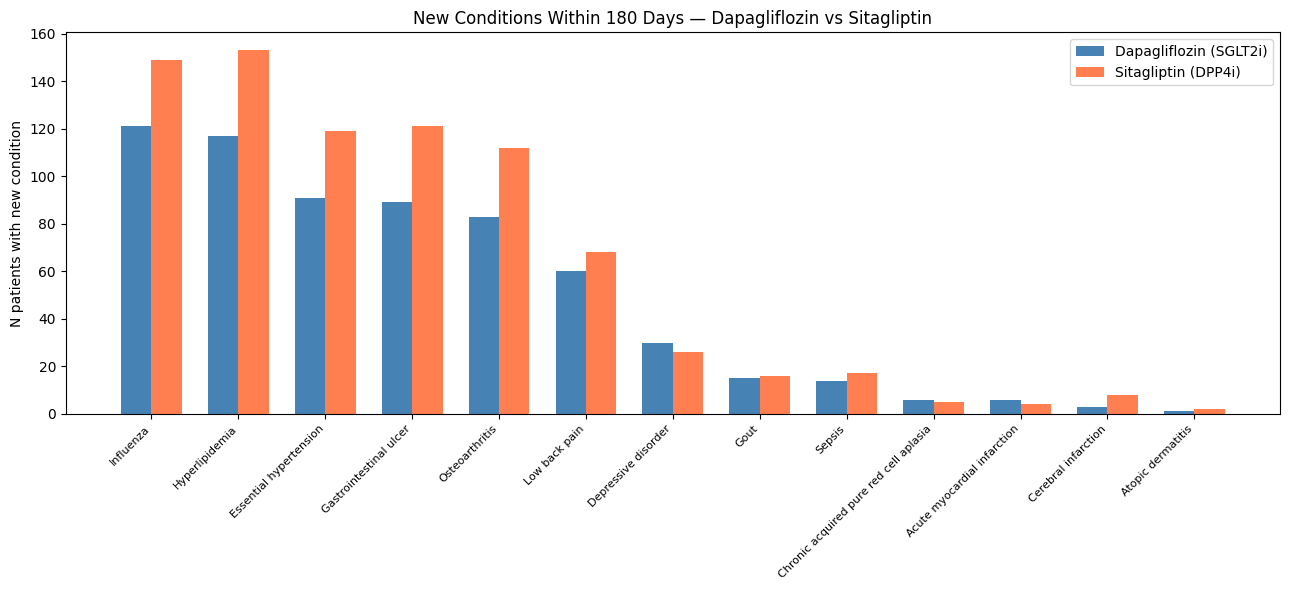

,new_condition,dapagliflozin,pct_dapa,sitagliptin,pct_sita
9,Influenza,121,8.40,149,9.20
8,Hyperlipidemia,117,8.10,153,9.40
5,Essential hypertension,91,6.30,119,7.30
6,Gastrointestinal ulcer,89,6.20,121,7.50
11,Osteoarthritis,83,5.70,112,6.90
10,Low back pain,60,4.20,68,4.20
4,Depressive disorder,30,2.10,26,1.60
7,Gout,15,1.00,16,1.00
12,Sepsis,14,1.00,17,1.00
3,Chronic acquired pure red cell aplasia,6,0.40,5,0.30


In [16]:
# Direct comparison: dapagliflozin vs sitagliptin — differential AE signal
df_dapa = get_new_conditions_t2('dapagliflozin', days=180, top_n=20).rename(
    columns={'n_patients':'dapagliflozin','pct_of_treated':'pct_dapa'})
df_sita = get_new_conditions_t2('sitagliptin',   days=180, top_n=20).rename(
    columns={'n_patients':'sitagliptin',  'pct_of_treated':'pct_sita'})

df_ae_cmp = df_dapa[['new_condition','dapagliflozin','pct_dapa']].merge(
    df_sita[['new_condition','sitagliptin','pct_sita']],
    on='new_condition', how='outer'
).fillna(0).sort_values('dapagliflozin', ascending=False).head(15)

fig, ax = plt.subplots(figsize=(13, 6))
x = range(len(df_ae_cmp))
w = 0.35
ax.bar([i-w/2 for i in x], df_ae_cmp['dapagliflozin'], w, label='Dapagliflozin (SGLT2i)', color='steelblue')
ax.bar([i+w/2 for i in x], df_ae_cmp['sitagliptin'],   w, label='Sitagliptin (DPP4i)',   color='coral')
ax.set_xticks(list(x))
ax.set_xticklabels(df_ae_cmp['new_condition'], rotation=45, ha='right', fontsize=8)
ax.set_ylabel('N patients with new condition')
ax.set_title('New Conditions Within 180 Days — Dapagliflozin vs Sitagliptin')
ax.legend()
plt.tight_layout()
plt.savefig('t2dm_ae_dapa_vs_sita.png', dpi=150, bbox_inches='tight')
plt.show()

df_ae_cmp

## 8. Co-morbidities

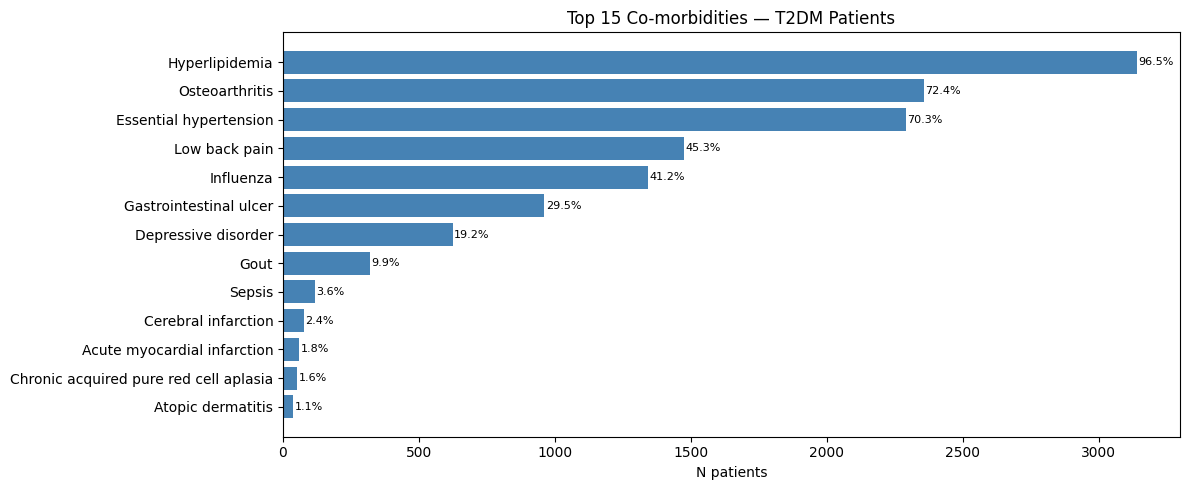

,condition,n_patients,pct
0,Hyperlipidemia,3142,96.50
1,Osteoarthritis,2356,72.40
2,Essential hypertension,2290,70.30
3,Low back pain,1474,45.30
4,Influenza,1342,41.20
5,Gastrointestinal ulcer,961,29.50
6,Depressive disorder,624,19.20
7,Gout,321,9.90
8,Sepsis,117,3.60
9,Cerebral infarction,78,2.40


In [17]:
df_comorbid_t2 = con.execute("""
    WITH t2 AS (
        SELECT DISTINCT co.person_id FROM main.condition_occurrence co
        JOIN main.concept c ON co.condition_concept_id = c.concept_id
        WHERE c.concept_name ILIKE '%type 2 diabetes mellitus%' AND c.standard_concept = 'S'
    )
    SELECT c.concept_name AS condition,
           COUNT(DISTINCT co.person_id) AS n_patients,
           ROUND(COUNT(DISTINCT co.person_id)*100.0/(SELECT COUNT(*) FROM t2),1) AS pct
    FROM main.condition_occurrence co
    JOIN main.concept c ON co.condition_concept_id = c.concept_id
    WHERE co.person_id IN (SELECT person_id FROM t2)
      AND c.concept_name NOT ILIKE '%diabetes%'
      AND c.standard_concept = 'S'
    GROUP BY 1 ORDER BY 2 DESC LIMIT 15
""").df()

fig, ax = plt.subplots(figsize=(12, 5))
ax.barh(df_comorbid_t2['condition'][::-1], df_comorbid_t2['n_patients'][::-1], color='steelblue')
ax.set_xlabel('N patients')
ax.set_title('Top 15 Co-morbidities — T2DM Patients')
for i, (_, row) in enumerate(df_comorbid_t2[::-1].reset_index().iterrows()):
    ax.text(row['n_patients']+5, i, f"{row['pct']}%", va='center', fontsize=8)
plt.tight_layout()
plt.show()

df_comorbid_t2

## 9. Full Clinical Profile — Example Patient

In [18]:
# Pick a patient on dapagliflozin (most relevant for causal analysis)
example_pid = con.execute("""
    WITH t2 AS (
        SELECT DISTINCT co.person_id FROM main.condition_occurrence co
        JOIN main.concept c ON co.condition_concept_id = c.concept_id
        WHERE c.concept_name ILIKE '%type 2 diabetes mellitus%' AND c.standard_concept = 'S'
    )
    SELECT de.person_id
    FROM main.drug_exposure de
    JOIN main.concept c ON de.drug_concept_id = c.concept_id
    WHERE de.person_id IN (SELECT person_id FROM t2)
      AND c.concept_name ILIKE '%dapagliflozin%' AND c.standard_concept = 'S'
    GROUP BY de.person_id
    ORDER BY COUNT(*) DESC LIMIT 1
""").fetchone()[0]

print(f'=== Clinical profile — Patient {example_pid} (on dapagliflozin) ===\n')

demo = con.execute(f"SELECT year_of_birth, gender_source_value FROM main.person WHERE person_id={example_pid}").df()
print(f"Birth: {int(demo.iloc[0]['year_of_birth'])}  Gender: {demo.iloc[0]['gender_source_value']}\n")

print('── Conditions ──────────────────────────────────────────')
print(con.execute(f"""
    SELECT co.condition_start_date, c.concept_name
    FROM main.condition_occurrence co
    JOIN main.concept c ON co.condition_concept_id = c.concept_id
    WHERE co.person_id = {example_pid} ORDER BY co.condition_start_date
""").df().to_string(index=False))

print('\n── Drug timeline ───────────────────────────────────────')
print(con.execute(f"""
    SELECT de.drug_exposure_start_date, c.concept_name AS drug
    FROM main.drug_exposure de
    JOIN main.concept c ON de.drug_concept_id = c.concept_id
    WHERE de.person_id = {example_pid} ORDER BY de.drug_exposure_start_date
""").df().to_string(index=False))

print('\n── HbA1c / Glucose measurements ────────────────────────')
print(con.execute(f"""
    SELECT m.measurement_date, c.concept_name, m.value_as_number, m.unit_source_value
    FROM main.measurement m
    JOIN main.concept c ON m.measurement_concept_id = c.concept_id
    WHERE m.person_id = {example_pid}
      AND c.concept_code IN ('4548-4','1558-6','18262-6','8480-6')
    ORDER BY m.measurement_date
""").df().to_string(index=False))

=== Clinical profile — Patient 791 (on dapagliflozin) ===

Birth: 1956  Gender: M

── Conditions ──────────────────────────────────────────
condition_start_date             concept_name
          2023-01-10            Low back pain
          2023-01-11           Hyperlipidemia
          2023-01-12           Osteoarthritis
          2023-01-31 Type 2 diabetes mellitus
          2023-02-05   Essential hypertension
          2023-04-19           Osteoarthritis
          2023-04-21 Type 2 diabetes mellitus
          2023-04-24            Low back pain
          2023-05-28   Essential hypertension
          2023-06-24 Type 2 diabetes mellitus
          2023-07-08           Hyperlipidemia
          2023-07-11           Osteoarthritis
          2023-07-27            Low back pain
          2023-09-09 Type 2 diabetes mellitus
          2023-09-21   Essential hypertension
          2023-10-17            Low back pain
          2023-11-07           Osteoarthritis
          2023-11-08 Type 2 diab

## 9b. Observations — T2DM Patient
Observation coverage for T2DM patients + all observations for an example patient on dapagliflozin.

In [19]:
# Observations coverage + all observations for a T2DM patient on dapagliflozin
obs_cov = con.execute("""
    WITH t2 AS (
        SELECT DISTINCT co.person_id FROM main.condition_occurrence co
        JOIN main.concept c ON co.condition_concept_id = c.concept_id
        WHERE c.concept_name ILIKE '%type 2 diabetes mellitus%'
          AND c.standard_concept = 'S'
    )
    SELECT COUNT(DISTINCT t2.person_id)              AS total_t2dm,
           COUNT(DISTINCT o.person_id)               AS with_observations,
           ROUND(COUNT(DISTINCT o.person_id)*100.0 /
                 COUNT(DISTINCT t2.person_id), 1)    AS pct_coverage
    FROM t2 LEFT JOIN main.observation o ON t2.person_id = o.person_id
""").df()
print("Observation coverage - T2DM patients:")
print(obs_cov.to_string(index=False))

top_obs = con.execute("""
    WITH t2 AS (
        SELECT DISTINCT co.person_id FROM main.condition_occurrence co
        JOIN main.concept c ON co.condition_concept_id = c.concept_id
        WHERE c.concept_name ILIKE '%type 2 diabetes mellitus%' AND c.standard_concept = 'S'
    )
    SELECT o.person_id, COUNT(*) AS n_obs
    FROM main.observation o
    JOIN main.drug_exposure de ON o.person_id = de.person_id
    JOIN main.concept cd ON de.drug_concept_id = cd.concept_id
    WHERE o.person_id IN (SELECT person_id FROM t2)
      AND cd.concept_name ILIKE '%dapagliflozin%' AND cd.standard_concept = 'S'
    GROUP BY o.person_id ORDER BY n_obs DESC LIMIT 1
""").df()
obs_pid = int(top_obs["person_id"].iloc[0])
print(
    f"Example patient (dapagliflozin, most obs): {obs_pid} - "
    f"{int(top_obs['n_obs'].iloc[0])} observations"
)

df_obs_t2 = con.execute(f"""
    SELECT o.observation_date,
           COALESCE(c.concept_name, 'UNMAPPED') AS observation,
           o.observation_source_value,
           o.value_as_string,
           o.value_as_number
    FROM main.observation o
    LEFT JOIN main.concept c ON o.observation_concept_id = c.concept_id
    WHERE o.person_id = {obs_pid}
    ORDER BY o.observation_date
""").df()
df_obs_t2


Observation coverage - T2DM patients:
 total_t2dm  with_observations  pct_coverage
       3256               3256        100.00


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Example patient (dapagliflozin, most obs): 7369 - 255 observations


,observation_date,observation,observation_source_value,value_as_string,value_as_number
0,2023-01-11,Metatarsalgia,HSDN:D037061:Metatarsalgia,present,NaN
1,2023-01-11,Pain threshold,HSDN:D017288:Pain Threshold,present,NaN
2,2023-01-11,Chronic nociceptive pain,HSDN:D059226:Nociceptive Pain,present,NaN
3,2023-01-27,Angina pectoris,HSDN:D000787:Angina Pectoris,present,NaN
4,2023-01-27,Snoring,HSDN:D012913:Snoring,present,NaN
...,...,...,...,...,...
80,2024-10-27,Insulin coma,HSDN:D007331:Insulin Coma,present,NaN
81,2024-10-30,Xanthoma planum,HSDN:D014972:Xanthoma,present,NaN
82,2024-10-30,Fatigue,HSDN:D005221:Fatigue,present,NaN
83,2024-12-05,Abdominal pain,HSDN:D015746:Abdominal Pain,present,NaN


## 9c. Full Clinical Profile (extended)
Conditions, drug timeline, measurements and observations for the same patient.

In [20]:
print(f"=== Full Clinical Profile - Patient {obs_pid} (T2DM on dapagliflozin) ===")

demo = con.execute(f"SELECT year_of_birth, gender_source_value, race_source_value FROM main.person WHERE person_id={obs_pid}").df().iloc[0]
print(f"Birth: {int(demo['year_of_birth'])}  Gender: {demo['gender_source_value']}  Race: {demo['race_source_value']}")

print("-- Conditions --")
print(con.execute(f"""
    SELECT co.condition_start_date, c.concept_name AS condition
    FROM main.condition_occurrence co
    JOIN main.concept c ON co.condition_concept_id = c.concept_id
    WHERE co.person_id = {obs_pid} ORDER BY co.condition_start_date
""").df().to_string(index=False))

print("\n-- Drug timeline --")
print(con.execute(f"""
    SELECT de.drug_exposure_start_date, de.drug_exposure_end_date, c.concept_name AS drug
    FROM main.drug_exposure de
    JOIN main.concept c ON de.drug_concept_id = c.concept_id
    WHERE de.person_id = {obs_pid} ORDER BY de.drug_exposure_start_date
""").df().to_string(index=False))

print("\n-- All measurements --")
print(con.execute(f"""
    SELECT m.measurement_date, c.concept_name AS measure,
           m.value_as_number, m.unit_source_value
    FROM main.measurement m
    JOIN main.concept c ON m.measurement_concept_id = c.concept_id
    WHERE m.person_id = {obs_pid} ORDER BY m.measurement_date
""").df().to_string(index=False))

print("\n-- Observations --")
print(con.execute(f"""
    SELECT o.observation_date,
           COALESCE(c.concept_name, 'UNMAPPED') AS observation,
           o.observation_source_value
    FROM main.observation o
    LEFT JOIN main.concept c ON o.observation_concept_id = c.concept_id
    WHERE o.person_id = {obs_pid} ORDER BY o.observation_date
""").df().to_string(index=False))


=== Full Clinical Profile - Patient 7369 (T2DM on dapagliflozin) ===
Birth: 1952  Gender: M  Race: Korean
-- Conditions --
condition_start_date                condition
          2023-01-11           Osteoarthritis
          2023-01-20            Low back pain
          2023-01-27   Essential hypertension
          2023-02-10           Hyperlipidemia
          2023-02-17 Type 2 diabetes mellitus
          2023-04-05 Type 2 diabetes mellitus
          2023-04-08           Osteoarthritis
          2023-04-29                Influenza
          2023-05-10 Type 2 diabetes mellitus
          2023-05-14           Hyperlipidemia
          2023-06-13                Influenza
          2023-06-27 Type 2 diabetes mellitus
          2023-07-03   Gastrointestinal ulcer
          2023-07-08           Osteoarthritis
          2023-07-22   Gastrointestinal ulcer
          2023-07-28   Gastrointestinal ulcer
          2023-08-02                Influenza
          2023-08-07 Type 2 diabetes mellitus
   

## 10. Table 1 — Confounder Balance
Are dapagliflozin and sitagliptin patients comparable on key covariates at the index date?  
If distributions are similar → good baseline comparability before any adjustment.

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Dapagliflozin : 1078 patients
Sitagliptin   : 1268 patients



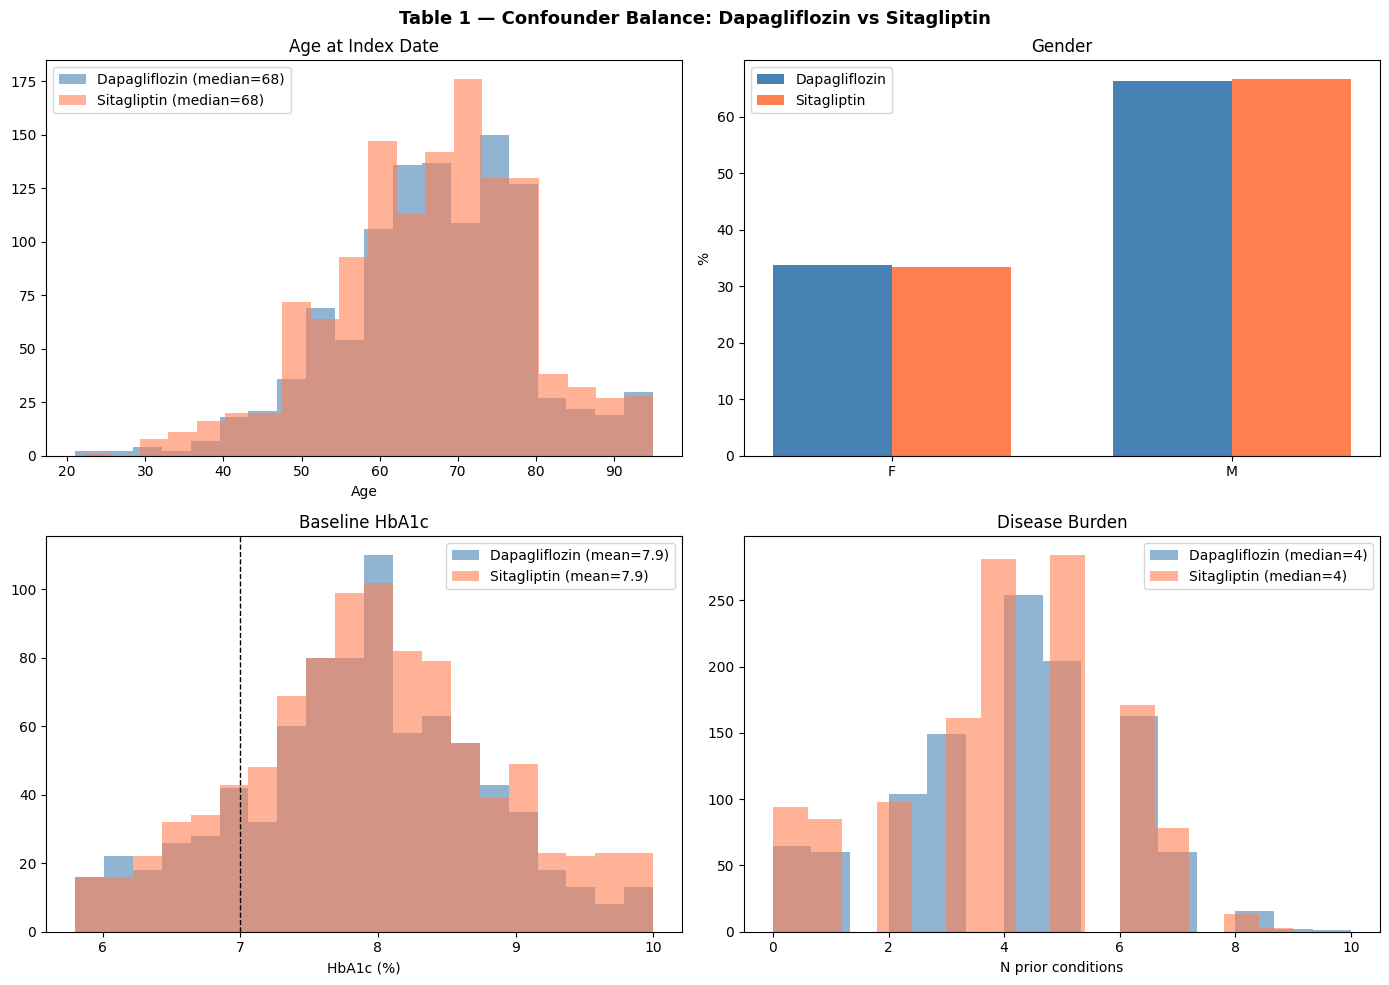

In [21]:

# Table 1 — Confounder balance: dapagliflozin vs sitagliptin at index date
df_cohort = con.execute("""
    WITH t2 AS (
        SELECT DISTINCT co.person_id FROM main.condition_occurrence co
        JOIN main.concept c ON co.condition_concept_id = c.concept_id
        WHERE c.concept_name ILIKE '%type 2 diabetes mellitus%' AND c.standard_concept = 'S'
    ),
    dapa AS (
        SELECT de.person_id, MIN(de.drug_exposure_start_date) AS index_date
        FROM main.drug_exposure de JOIN main.concept c ON de.drug_concept_id = c.concept_id
        WHERE c.concept_name ILIKE '%dapagliflozin%' AND c.standard_concept = 'S'
          AND de.person_id IN (SELECT person_id FROM t2)
        GROUP BY de.person_id
    ),
    sita AS (
        SELECT de.person_id, MIN(de.drug_exposure_start_date) AS index_date
        FROM main.drug_exposure de JOIN main.concept c ON de.drug_concept_id = c.concept_id
        WHERE c.concept_name ILIKE '%sitagliptin%' AND c.standard_concept = 'S'
          AND de.person_id IN (SELECT person_id FROM t2)
        GROUP BY de.person_id
    ),
    cohort AS (
        SELECT COALESCE(d.person_id, s.person_id) AS person_id,
               CASE
                   WHEN d.person_id IS NOT NULL AND s.person_id IS NULL THEN 'dapagliflozin'
                   WHEN d.person_id IS NULL AND s.person_id IS NOT NULL THEN 'sitagliptin'
                   WHEN d.index_date < s.index_date THEN 'dapagliflozin'
                   WHEN s.index_date < d.index_date THEN 'sitagliptin'
               END AS drug_group,
               CASE
                   WHEN d.person_id IS NOT NULL AND s.person_id IS NULL THEN d.index_date
                   WHEN d.person_id IS NULL AND s.person_id IS NOT NULL THEN s.index_date
                   WHEN d.index_date < s.index_date THEN d.index_date
                   WHEN s.index_date < d.index_date THEN s.index_date
               END AS index_date
        FROM dapa d FULL OUTER JOIN sita s ON d.person_id = s.person_id
        WHERE CASE WHEN d.person_id IS NOT NULL AND s.person_id IS NULL THEN TRUE
                   WHEN d.person_id IS NULL AND s.person_id IS NOT NULL THEN TRUE
                   WHEN d.index_date != s.index_date THEN TRUE ELSE FALSE END
    ),
    hba1c_pre AS (
        SELECT m.person_id, AVG(m.value_as_number) AS hba1c_baseline
        FROM main.measurement m
        JOIN main.concept cm ON m.measurement_concept_id = cm.concept_id
        JOIN cohort c ON m.person_id = c.person_id
        WHERE cm.concept_code = '4548-4' AND m.value_as_number BETWEEN 4 AND 15
          AND m.measurement_date < c.index_date
        GROUP BY m.person_id
    ),
    comorbidities AS (
        SELECT co.person_id, COUNT(DISTINCT co.condition_concept_id) AS n_conditions
        FROM main.condition_occurrence co
        JOIN cohort c ON co.person_id = c.person_id
        WHERE co.condition_start_date < c.index_date
        GROUP BY co.person_id
    )
    SELECT c.person_id, c.drug_group, c.index_date,
           2024 - p.year_of_birth                    AS age,
           p.gender_source_value                       AS gender,
           ROUND(h.hba1c_baseline, 2)                 AS hba1c_baseline,
           COALESCE(cm.n_conditions, 0)               AS n_conditions_prior
    FROM cohort c
    JOIN main.person p ON c.person_id = p.person_id
    LEFT JOIN hba1c_pre h  ON c.person_id = h.person_id
    LEFT JOIN comorbidities cm ON c.person_id = cm.person_id
    WHERE c.drug_group IS NOT NULL
""").df()

print(f"Dapagliflozin : {(df_cohort['drug_group']=='dapagliflozin').sum()} patients")
print(f"Sitagliptin   : {(df_cohort['drug_group']=='sitagliptin').sum()} patients\n")

dapa_g = df_cohort[df_cohort['drug_group'] == 'dapagliflozin']
sita_g = df_cohort[df_cohort['drug_group'] == 'sitagliptin']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Table 1 — Confounder Balance: Dapagliflozin vs Sitagliptin', fontsize=13, fontweight='bold')

axes[0,0].hist(dapa_g['age'].dropna(), bins=20, alpha=0.6, color='steelblue',
               label=f'Dapagliflozin (median={dapa_g["age"].median():.0f})')
axes[0,0].hist(sita_g['age'].dropna(), bins=20, alpha=0.6, color='coral',
               label=f'Sitagliptin (median={sita_g["age"].median():.0f})')
axes[0,0].set_xlabel('Age'); axes[0,0].set_title('Age at Index Date'); axes[0,0].legend()

dapa_gen = dapa_g['gender'].value_counts(normalize=True).mul(100)
sita_gen = sita_g['gender'].value_counts(normalize=True).mul(100)
genders = sorted(set(dapa_gen.index.tolist() + sita_gen.index.tolist()))
x, w = range(len(genders)), 0.35
axes[0,1].bar([i-w/2 for i in x], [dapa_gen.get(g,0) for g in genders], w, label='Dapagliflozin', color='steelblue')
axes[0,1].bar([i+w/2 for i in x], [sita_gen.get(g,0) for g in genders], w, label='Sitagliptin', color='coral')
axes[0,1].set_xticks(list(x)); axes[0,1].set_xticklabels(genders)
axes[0,1].set_ylabel('%'); axes[0,1].set_title('Gender'); axes[0,1].legend()

axes[1,0].hist(dapa_g['hba1c_baseline'].dropna(), bins=20, alpha=0.6, color='steelblue',
               label=f'Dapagliflozin (mean={dapa_g["hba1c_baseline"].mean():.1f})')
axes[1,0].hist(sita_g['hba1c_baseline'].dropna(), bins=20, alpha=0.6, color='coral',
               label=f'Sitagliptin (mean={sita_g["hba1c_baseline"].mean():.1f})')
axes[1,0].axvline(7.0, color='black', linestyle='--', linewidth=1)
axes[1,0].set_xlabel('HbA1c (%)'); axes[1,0].set_title('Baseline HbA1c'); axes[1,0].legend()

axes[1,1].hist(dapa_g['n_conditions_prior'].dropna(), bins=15, alpha=0.6, color='steelblue',
               label=f'Dapagliflozin (median={dapa_g["n_conditions_prior"].median():.0f})')
axes[1,1].hist(sita_g['n_conditions_prior'].dropna(), bins=15, alpha=0.6, color='coral',
               label=f'Sitagliptin (median={sita_g["n_conditions_prior"].median():.0f})')
axes[1,1].set_xlabel('N prior conditions'); axes[1,1].set_title('Disease Burden'); axes[1,1].legend()

plt.tight_layout()
plt.savefig('t2dm_table1_balance.png', dpi=150, bbox_inches='tight')
plt.show()


## 11. HbA1c Trajectory — Pre/Post Treatment Initiation
Mean HbA1c before and after first prescription of dapagliflozin vs sitagliptin.  
Validates HbA1c as a usable longitudinal outcome and reveals any pre-existing trend (parallel trends assumption).

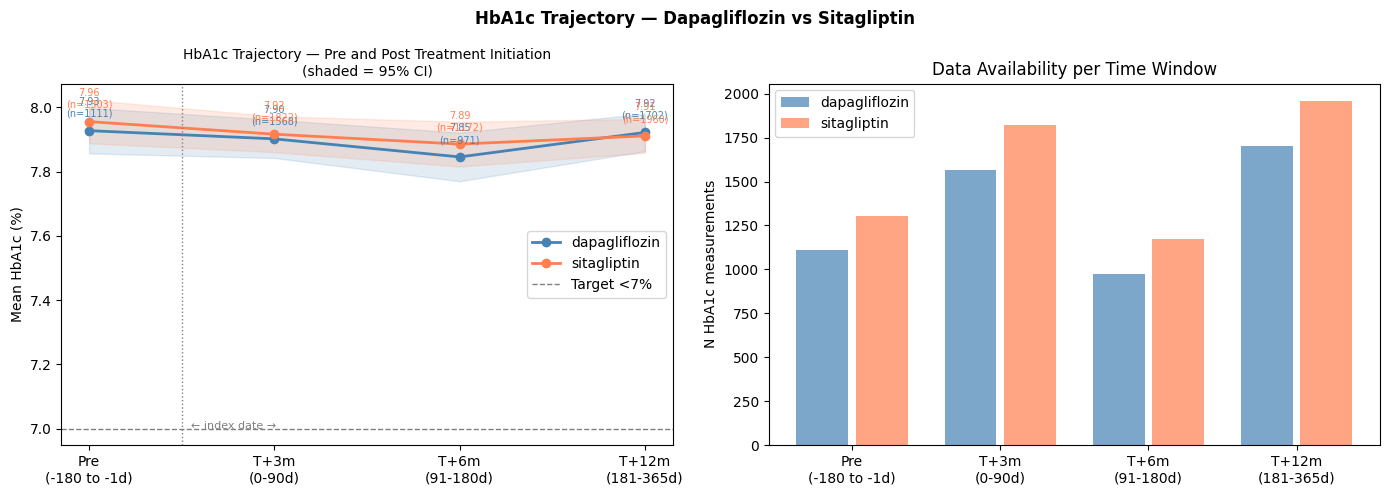

In [22]:

# HbA1c trajectory pre/post treatment initiation
# Fetch all HbA1c measurements for the dapagliflozin/sitagliptin cohort
patient_ids_tuple = tuple(df_cohort['person_id'].astype(int).tolist())

df_hba1c_raw = con.execute(f"""
    SELECT m.person_id, m.measurement_date, m.value_as_number AS hba1c
    FROM main.measurement m
    JOIN main.concept cm ON m.measurement_concept_id = cm.concept_id
    WHERE cm.concept_code = '4548-4'
      AND m.value_as_number BETWEEN 4 AND 15
      AND m.person_id IN {patient_ids_tuple}
""").df()

# Merge with cohort index dates
df_hba1c_raw = df_hba1c_raw.merge(
    df_cohort[['person_id','index_date','drug_group']], on='person_id', how='inner'
)
df_hba1c_raw['days'] = (
    pd.to_datetime(df_hba1c_raw['measurement_date']) -
    pd.to_datetime(df_hba1c_raw['index_date'])
).dt.days

# Time windows
windows = [
    ('Pre\n(-180 to -1d)',  -180,  -1),
    ('T+3m\n(0-90d)',          0,  90),
    ('T+6m\n(91-180d)',       91, 180),
    ('T+12m\n(181-365d)',    181, 365),
]

records = []
for group in ['dapagliflozin', 'sitagliptin']:
    g = df_hba1c_raw[df_hba1c_raw['drug_group'] == group]
    for label, d0, d1 in windows:
        w = g[(g['days'] >= d0) & (g['days'] <= d1)]['hba1c']
        records.append({'group': group, 'window': label,
                        'mean': w.mean(), 'se': w.sem(), 'n': len(w)})
df_traj = pd.DataFrame(records)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Trajectory lines
for group, color in [('dapagliflozin', 'steelblue'), ('sitagliptin', 'coral')]:
    g = df_traj[df_traj['group'] == group]
    x = range(len(windows))
    axes[0].plot(x, g['mean'], marker='o', color=color, linewidth=2, label=group)
    axes[0].fill_between(x,
                         g['mean'] - 1.96*g['se'],
                         g['mean'] + 1.96*g['se'],
                         color=color, alpha=0.15)
    for xi, (_, row) in zip(x, g.iterrows()):
        axes[0].annotate(f"{row['mean']:.2f}\n(n={row['n']})",
                         (xi, row['mean']), textcoords='offset points',
                         xytext=(0, 10), ha='center', fontsize=7, color=color)

axes[0].set_xticks(range(len(windows)))
axes[0].set_xticklabels([w[0] for w in windows])
axes[0].axhline(7.0, color='black', linestyle='--', linewidth=1, alpha=0.5, label='Target <7%')
axes[0].axvline(0.5, color='gray', linestyle=':', linewidth=1)
axes[0].text(0.55, axes[0].get_ylim()[0]+0.05, '← index date →', fontsize=8, color='gray')
axes[0].set_ylabel('Mean HbA1c (%)')
axes[0].set_title('HbA1c Trajectory — Pre and Post Treatment Initiation\n(shaded = 95% CI)', fontsize=10)
axes[0].legend()

# N observations per window
for group, color in [('dapagliflozin', 'steelblue'), ('sitagliptin', 'coral')]:
    g = df_traj[df_traj['group'] == group]
    x_pos = [i + (-0.2 if group == 'dapagliflozin' else 0.2) for i in range(len(windows))]
    axes[1].bar(x_pos, g['n'], 0.35, color=color, alpha=0.7, label=group)
axes[1].set_xticks(range(len(windows)))
axes[1].set_xticklabels([w[0] for w in windows])
axes[1].set_ylabel('N HbA1c measurements')
axes[1].set_title('Data Availability per Time Window')
axes[1].legend()

plt.suptitle('HbA1c Trajectory — Dapagliflozin vs Sitagliptin', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('t2dm_hba1c_trajectory.png', dpi=150, bbox_inches='tight')
plt.show()


## 12. Time to Treatment Switch
How long do patients stay on their first antidiabetic before switching to another?  
Informs the choice of follow-up window for the causal question.

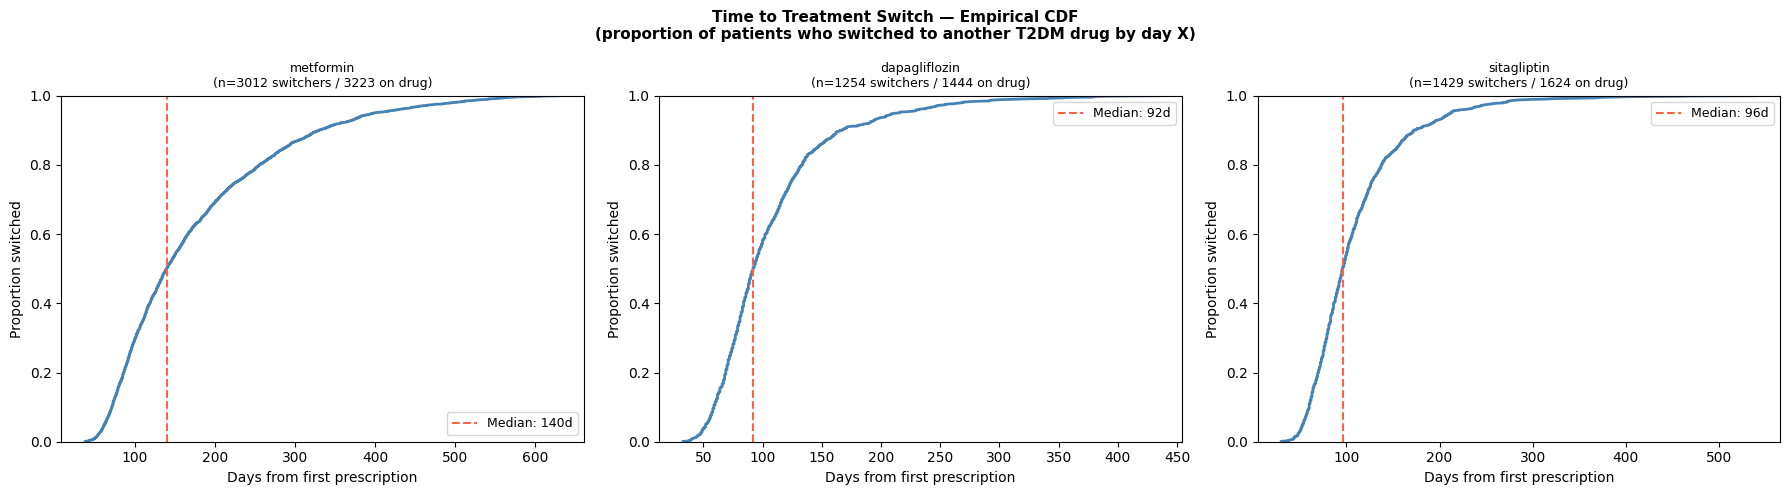

In [23]:

# Time to treatment switch — for metformin, dapagliflozin, sitagliptin
# "Switch" = patient receives a DIFFERENT T2DM-enriched drug after their first prescription

# Get T2DM-enriched drugs from the enrichment analysis (enrichment >= 3x)
enriched_drug_names = df_enrichment[df_enrichment['enrichment_ratio'] >= 3.0]['drug'].tolist()
enriched_ids_str = ','.join([
    str(r[0]) for r in con.execute(f"""
        SELECT concept_id FROM main.concept
        WHERE concept_name IN ({','.join(["'" + d.replace("'","''") + "'" for d in enriched_drug_names])})
          AND standard_concept = 'S' AND domain_id = 'Drug'
    """).fetchall()
])

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, drug in zip(axes, ['metformin', 'dapagliflozin', 'sitagliptin']):
    df_switch = con.execute(f"""
        WITH t2 AS (
            SELECT DISTINCT co.person_id FROM main.condition_occurrence co
            JOIN main.concept c ON co.condition_concept_id = c.concept_id
            WHERE c.concept_name ILIKE '%type 2 diabetes mellitus%' AND c.standard_concept = 'S'
        ),
        first_rx AS (
            SELECT de.person_id, MIN(de.drug_exposure_start_date) AS first_date,
                   de.drug_concept_id AS drug_id
            FROM main.drug_exposure de
            JOIN main.concept c ON de.drug_concept_id = c.concept_id
            WHERE c.concept_name ILIKE '%{drug}%' AND c.standard_concept = 'S'
              AND de.person_id IN (SELECT person_id FROM t2)
            GROUP BY de.person_id, de.drug_concept_id
        ),
        first_switch AS (
            SELECT de.person_id, MIN(de.drug_exposure_start_date) AS switch_date
            FROM main.drug_exposure de
            WHERE de.person_id IN (SELECT person_id FROM first_rx)
              AND de.drug_concept_id != (SELECT drug_id FROM first_rx fr WHERE fr.person_id = de.person_id LIMIT 1)
              AND de.drug_concept_id IN ({enriched_ids_str})
              AND de.drug_exposure_start_date > (SELECT first_date FROM first_rx fr WHERE fr.person_id = de.person_id LIMIT 1)
            GROUP BY de.person_id
        )
        SELECT DATEDIFF('day', fr.first_date, fs.switch_date) AS days_to_switch
        FROM first_rx fr
        LEFT JOIN first_switch fs ON fr.person_id = fs.person_id
        WHERE fs.switch_date IS NOT NULL
    """).df()

    if len(df_switch) > 0:
        days = df_switch['days_to_switch'].sort_values()
        # Empirical CDF
        cdf = [i / len(days) for i in range(1, len(days)+1)]
        ax.plot(days, cdf, color='steelblue', linewidth=2)
        ax.axvline(days.median(), color='tomato', linestyle='--',
                   label=f'Median: {days.median():.0f}d')
        ax.set_xlabel('Days from first prescription')
        ax.set_ylabel('Proportion switched')
        ax.set_title(f'{drug}\n(n={len(days)} switchers / {con.execute(f"""SELECT COUNT(DISTINCT de.person_id) FROM main.drug_exposure de JOIN main.concept c ON de.drug_concept_id=c.concept_id WHERE c.concept_name ILIKE \'%{drug}%\' AND c.standard_concept=\'S\' AND de.person_id IN (SELECT DISTINCT co.person_id FROM main.condition_occurrence co JOIN main.concept cc ON co.condition_concept_id=cc.concept_id WHERE cc.concept_name ILIKE \'%type 2 diabetes%\' AND cc.standard_concept=\'S\')""").fetchone()[0]} on drug)', fontsize=9)
        ax.legend(fontsize=9)
        ax.set_ylim(0, 1)
    else:
        ax.text(0.5, 0.5, 'No switches detected', ha='center', va='center')

plt.suptitle('Time to Treatment Switch — Empirical CDF\n(proportion of patients who switched to another T2DM drug by day X)',
             fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig('t2dm_time_to_switch.png', dpi=150, bbox_inches='tight')
plt.show()


## 13. Prevalent vs Incident T2DM
Can we distinguish patients who already had T2DM before their first hospital visit (prevalent) from those newly diagnosed during follow-up (incident)?  
Critical for applying a **new-user design** and avoiding prevalent-user bias.

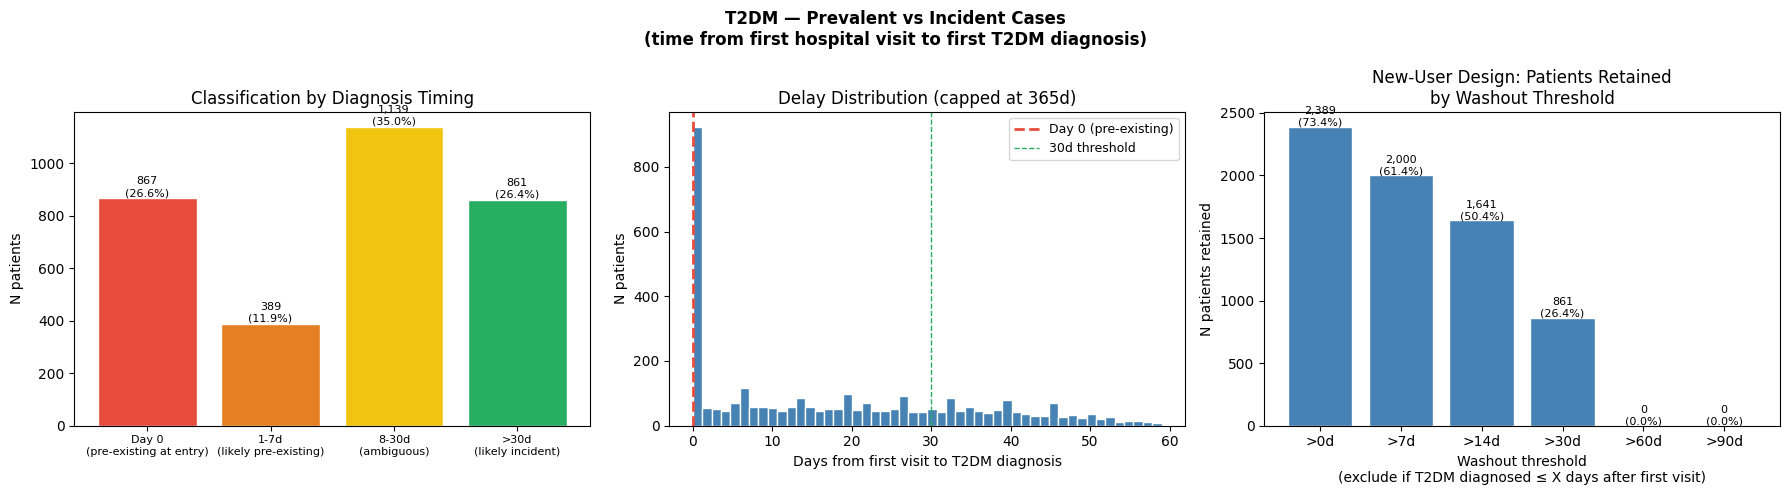

Summary:
  Day 0 (pre-existing at entry)                :   867 (26.6%)
  1-7d (likely pre-existing)                   :   389 (11.9%)
  8-30d (ambiguous)                            :  1139 (35.0%)
  >30d (likely incident)                       :   861 (26.4%)

Strict new-user (>30d washout) : 861 patients
Lenient new-user (>7d washout)  : 2,000 patients


In [24]:

# Prevalent vs Incident T2DM — timing of first diagnosis relative to first hospital visit
df_timing = con.execute("""
    WITH t2_first AS (
        SELECT co.person_id, MIN(co.condition_start_date) AS first_t2dm_date
        FROM main.condition_occurrence co
        JOIN main.concept c ON co.condition_concept_id = c.concept_id
        WHERE c.concept_name ILIKE '%type 2 diabetes mellitus%' AND c.standard_concept = 'S'
        GROUP BY co.person_id
    ),
    first_visit AS (
        SELECT person_id, MIN(visit_start_date) AS first_visit_date
        FROM main.visit_occurrence GROUP BY person_id
    )
    SELECT
        t2.person_id,
        t2.first_t2dm_date,
        fv.first_visit_date,
        DATEDIFF('day', fv.first_visit_date, t2.first_t2dm_date) AS delay_days
    FROM t2_first t2
    JOIN first_visit fv ON t2.person_id = fv.person_id
""").df()

def classify_timing(d):
    if d == 0:   return 'Day 0\n(pre-existing at entry)'
    if d <= 7:   return '1-7d\n(likely pre-existing)'
    if d <= 30:  return '8-30d\n(ambiguous)'
    return '>30d\n(likely incident)'

order = ['Day 0\n(pre-existing at entry)', '1-7d\n(likely pre-existing)',
         '8-30d\n(ambiguous)', '>30d\n(likely incident)']
colors_t = ['#e74c3c', '#e67e22', '#f1c40f', '#27ae60']

df_timing['group'] = df_timing['delay_days'].apply(classify_timing)
counts = df_timing['group'].value_counts().reindex(order)
n_total = len(df_timing)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('T2DM — Prevalent vs Incident Cases\n(time from first hospital visit to first T2DM diagnosis)',
             fontsize=12, fontweight='bold')

# Bar chart of groups
bars = axes[0].bar(range(len(order)), counts.values, color=colors_t, edgecolor='white')
axes[0].set_xticks(range(len(order)))
axes[0].set_xticklabels(order, fontsize=8)
axes[0].set_ylabel('N patients')
axes[0].set_title('Classification by Diagnosis Timing')
for bar, val in zip(bars, counts.values):
    axes[0].text(bar.get_x()+bar.get_width()/2, bar.get_height()+8,
                 f'{val:,}\n({val/n_total*100:.1f}%)', ha='center', fontsize=8)

# Histogram of delay days (0-365)
clipped = df_timing[df_timing['delay_days'].between(0, 365)]
axes[1].hist(clipped['delay_days'], bins=50, color='steelblue', edgecolor='white')
axes[1].axvline(0,  color='#e74c3c', linestyle='--', linewidth=2, label='Day 0 (pre-existing)')
axes[1].axvline(30, color='#27ae60', linestyle='--', linewidth=1, label='30d threshold')
axes[1].set_xlabel('Days from first visit to T2DM diagnosis')
axes[1].set_ylabel('N patients')
axes[1].set_title('Delay Distribution (capped at 365d)')
axes[1].legend(fontsize=9)

# Impact of washout on new-user design
cutoffs = [0, 7, 14, 30, 60, 90]
n_retained = [(df_timing['delay_days'] > c).sum() for c in cutoffs]
pct_retained = [n/n_total*100 for n in n_retained]
bars2 = axes[2].bar(range(len(cutoffs)), n_retained, color='steelblue', edgecolor='white')
axes[2].set_xticks(range(len(cutoffs)))
axes[2].set_xticklabels([f'>{c}d' for c in cutoffs])
axes[2].set_xlabel('Washout threshold\n(exclude if T2DM diagnosed ≤ X days after first visit)')
axes[2].set_ylabel('N patients retained')
axes[2].set_title('New-User Design: Patients Retained\nby Washout Threshold')
for bar, (n, p) in zip(bars2, zip(n_retained, pct_retained)):
    axes[2].text(bar.get_x()+bar.get_width()/2, bar.get_height()+8,
                 f'{n:,}\n({p:.1f}%)', ha='center', fontsize=8)

plt.tight_layout()
plt.savefig('t2dm_prevalent_vs_incident.png', dpi=150, bbox_inches='tight')
plt.show()

print('Summary:')
for g, c in counts.items():
    print(f'  {g.replace(chr(10)," "):<45}: {c:>5} ({c/n_total*100:.1f}%)')
print(f'\nStrict new-user (>30d washout) : {int((df_timing["delay_days"]>30).sum()):,} patients')
print(f'Lenient new-user (>7d washout)  : {int((df_timing["delay_days"]>7).sum()):,} patients')


## 14. Temporal Analysis — Follow-up Window Selection
Three data-driven analyses to determine the optimal follow-up window:
1. Cumulative incidence of new conditions over time
2. Window vs contamination trade-off
3. Monthly HbA1c trajectory (granular pre/post)

In [25]:
# ── 14a–c: data preparation ─────────────────────────────────────────────────
# Requires df_cohort (Section 10) and df_enrichment (Section 2)

patient_ids_t = tuple(df_cohort['person_id'].astype(int).tolist())

# -- All conditions for cohort patients --
df_conds_all = con.execute(f"""
    SELECT co.person_id, co.condition_concept_id, co.condition_start_date
    FROM main.condition_occurrence co
    WHERE co.person_id IN {patient_ids_t} AND co.condition_concept_id != 0
""").df()
df_conds_all = df_conds_all.merge(
    df_cohort[['person_id','index_date','drug_group']], on='person_id', how='inner'
)
df_conds_all['days'] = (
    pd.to_datetime(df_conds_all['condition_start_date']) -
    pd.to_datetime(df_conds_all['index_date'])
).dt.days

# Pre-existing = any occurrence on or before index date
pre_keys = set(
    df_conds_all[df_conds_all['days'] <= 0]
    .apply(lambda r: (r['person_id'], r['condition_concept_id']), axis=1)
)
df_new = df_conds_all[
    (df_conds_all['days'] > 0) &
    (~df_conds_all.apply(lambda r: (r['person_id'], r['condition_concept_id']) in pre_keys, axis=1))
]

first_event = df_new.groupby(['person_id','drug_group'])['days'].min().reset_index()
first_event.columns = ['person_id','drug_group','days_to_event']
cohort_ev = df_cohort[['person_id','drug_group']].merge(
    first_event, on=['person_id','drug_group'], how='left'
)

# -- Cumulative incidence --
thresholds = range(0, 366, 5)
ci_records = []
for group in ['dapagliflozin', 'sitagliptin']:
    g = cohort_ev[cohort_ev['drug_group'] == group]
    n = len(g)
    for t in thresholds:
        ci_records.append({
            'group': group, 'day': t,
            'cum_incidence': (g['days_to_event'] <= t).sum() / n * 100
        })
df_ci = pd.DataFrame(ci_records)

# -- Window vs contamination trade-off --
# Use time-to-switch already computed in Section 12 concept ids approach
enriched_names = df_enrichment[df_enrichment['enrichment_ratio'] >= 3.0]['drug'].tolist()
enriched_ids = [r[0] for r in con.execute(
    'SELECT concept_id FROM main.concept WHERE concept_name IN ('
    + ','.join(["'" + d.replace("'","''") + "'" for d in enriched_names])
    + ") AND standard_concept = 'S' AND domain_id = 'Drug'"
).fetchall()]
enr_str = ','.join(str(x) for x in enriched_ids)

switch_days = []
for _, row in df_cohort.iterrows():
    pid = int(row['person_id'])
    ix  = str(row['index_date'])[:10]
    drug_g = row['drug_group']
    current_ids = [r[0] for r in con.execute(f"""
        SELECT DISTINCT de.drug_concept_id FROM main.drug_exposure de
        JOIN main.concept c ON de.drug_concept_id = c.concept_id
        WHERE de.person_id = {pid}
          AND de.drug_exposure_start_date <= '{ix}'
          AND c.concept_name ILIKE '%{drug_g}%' AND c.standard_concept = 'S'
    """).fetchall()]
    if not current_ids:
        switch_days.append({'person_id': pid, 'days_to_switch': None})
        continue
    excl = ','.join(str(x) for x in current_ids)
    r = con.execute(f"""
        SELECT DATEDIFF('day', '{ix}', MIN(de.drug_exposure_start_date))
        FROM main.drug_exposure de
        WHERE de.person_id = {pid}
          AND de.drug_concept_id NOT IN ({excl})
          AND de.drug_concept_id IN ({enr_str})
          AND de.drug_exposure_start_date > '{ix}'
    """).fetchone()[0]
    switch_days.append({'person_id': pid, 'days_to_switch': r})

df_sw = pd.DataFrame(switch_days)

n_with_event = cohort_ev['days_to_event'].notna().sum()
windows_list = [30, 60, 90, 120, 180, 270, 365]
tradeoff_rows = []
for w in windows_list:
    n_ev = int((cohort_ev['days_to_event'] <= w).sum())
    n_sw = int((df_sw['days_to_switch'].dropna() < w).sum())
    tradeoff_rows.append({
        'window_days': w,
        'pct_events':   round(n_ev / n_with_event * 100, 1),
        'pct_switched': round(n_sw / len(df_cohort) * 100, 1),
        'net_gain':     round(n_ev / n_with_event * 100 - n_sw / len(df_cohort) * 100, 1)
    })
df_tradeoff = pd.DataFrame(tradeoff_rows)

# -- Monthly HbA1c --
if 'df_hba1c_raw' not in dir():
    df_hba1c_raw = con.execute(f"""
        SELECT m.person_id, m.measurement_date, m.value_as_number AS hba1c
        FROM main.measurement m
        JOIN main.concept cm ON m.measurement_concept_id = cm.concept_id
        WHERE cm.concept_code = '4548-4'
          AND m.value_as_number BETWEEN 4 AND 15
          AND m.person_id IN {patient_ids_t}
    """).df()
    df_hba1c_raw = df_hba1c_raw.merge(
        df_cohort[['person_id','index_date','drug_group']], on='person_id', how='inner'
    )
    df_hba1c_raw['days'] = (
        pd.to_datetime(df_hba1c_raw['measurement_date']) -
        pd.to_datetime(df_hba1c_raw['index_date'])
    ).dt.days

monthly_windows = [
    ('M-6', -180, -91), ('M-3', -90, -1),
    ('M+1',   0,  30),  ('M+3',  31,  90),
    ('M+6',  91, 180),  ('M+9', 181, 270), ('M+12', 271, 365),
]
monthly_recs = []
for group in ['dapagliflozin', 'sitagliptin']:
    g = df_hba1c_raw[df_hba1c_raw['drug_group'] == group]
    for label, d0, d1 in monthly_windows:
        w = g[(g['days'] >= d0) & (g['days'] <= d1)]['hba1c']
        monthly_recs.append({'group': group, 'period': label,
                             'mean': w.mean(), 'se': w.sem(), 'n': len(w)})
df_monthly = pd.DataFrame(monthly_recs)

print('All data prepared. Run next cell to plot.')
print(df_tradeoff.to_string(index=False))


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

All data prepared. Run next cell to plot.
 window_days  pct_events  pct_switched  net_gain
          30       55.00          0.00     55.00
          60       64.90          7.90     56.90
          90       70.30         37.30     33.00
         120       74.70         60.00     14.70
         180       80.60         79.80      0.80
         270       87.50         87.40      0.10
         365       93.60         88.70      4.90


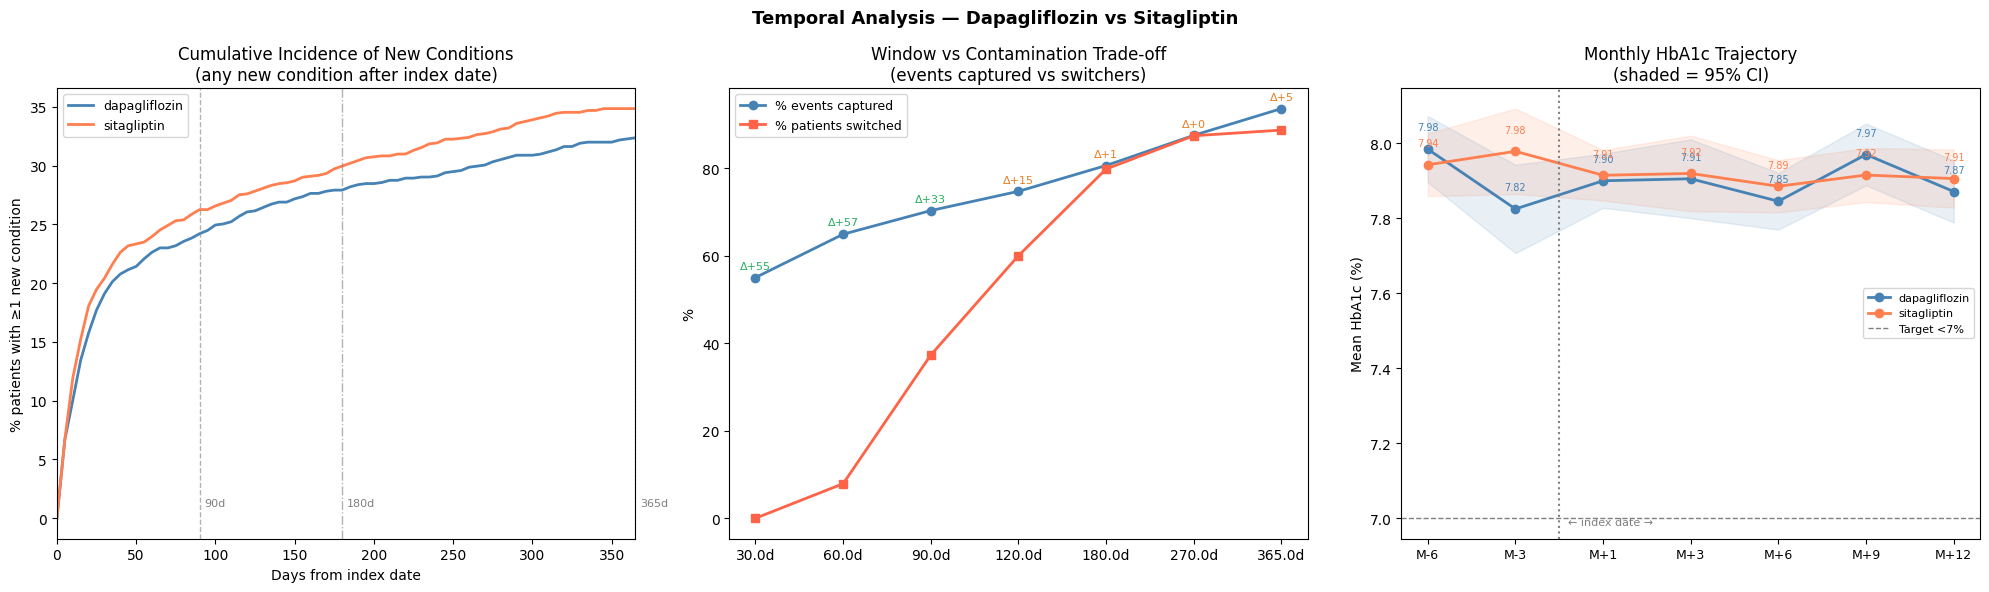

In [26]:
# ── Plots ─────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle('Temporal Analysis — Dapagliflozin vs Sitagliptin', fontsize=13, fontweight='bold')

# Plot 1 — Cumulative incidence
for group, color in [('dapagliflozin','steelblue'), ('sitagliptin','coral')]:
    g = df_ci[df_ci['group'] == group]
    axes[0].plot(g['day'], g['cum_incidence'], color=color, linewidth=2, label=group)
for w, ls, lbl in [(90,'--','90d'), (180,'-.','180d'), (365,':','365d')]:
    axes[0].axvline(w, color='gray', linestyle=ls, linewidth=1, alpha=0.6)
    axes[0].text(w+3, 1, lbl, fontsize=8, color='gray')
axes[0].set_xlabel('Days from index date')
axes[0].set_ylabel('% patients with ≥1 new condition')
axes[0].set_title('Cumulative Incidence of New Conditions\n(any new condition after index date)')
axes[0].legend(fontsize=9)
axes[0].set_xlim(0, 365)

# Plot 2 — Trade-off
x2 = range(len(df_tradeoff))
axes[1].plot(x2, df_tradeoff['pct_events'],   color='steelblue', marker='o', linewidth=2, label='% events captured')
axes[1].plot(x2, df_tradeoff['pct_switched'], color='tomato',    marker='s', linewidth=2, label='% patients switched')
axes[1].set_xticks(list(x2))
axes[1].set_xticklabels([f"{r['window_days']}d" for _,r in df_tradeoff.iterrows()])
axes[1].set_ylabel('%')
axes[1].set_title('Window vs Contamination Trade-off\n(events captured vs switchers)')
axes[1].legend(fontsize=9)
# Annotate net gain
for i, (_, row) in enumerate(df_tradeoff.iterrows()):
    color = '#27ae60' if row['net_gain'] > 20 else '#e67e22' if row['net_gain'] > 0 else '#e74c3c'
    axes[1].text(i, max(row['pct_events'], row['pct_switched'])+2,
                 f"Δ{row['net_gain']:+.0f}", ha='center', fontsize=8, color=color)

# Plot 3 — Monthly HbA1c
periods = [r[0] for r in monthly_windows]
x3 = range(len(periods))
for group, color in [('dapagliflozin','steelblue'), ('sitagliptin','coral')]:
    g = df_monthly[df_monthly['group'] == group].set_index('period').reindex(periods)
    axes[2].plot(x3, g['mean'], marker='o', color=color, linewidth=2, label=group)
    axes[2].fill_between(x3,
                         g['mean'] - 1.96*g['se'],
                         g['mean'] + 1.96*g['se'],
                         color=color, alpha=0.12)
    for xi, (_, row) in zip(x3, g.iterrows()):
        if not pd.isna(row['mean']):
            axes[2].text(xi, row['mean']+0.05, f"{row['mean']:.2f}",
                         ha='center', fontsize=7, color=color)
axes[2].axvline(1.5, color='gray', linestyle=':', linewidth=1.5)
axes[2].axhline(7.0, color='black', linestyle='--', linewidth=1, alpha=0.5, label='Target <7%')
axes[2].set_xticks(list(x3))
axes[2].set_xticklabels(periods, fontsize=9)
axes[2].set_ylabel('Mean HbA1c (%)')
axes[2].set_title('Monthly HbA1c Trajectory\n(shaded = 95% CI)')
axes[2].legend(fontsize=8)
# Mark index date
ymin, ymax = axes[2].get_ylim()
axes[2].text(1.6, ymin + (ymax-ymin)*0.03, '← index date →', fontsize=8, color='gray')

plt.tight_layout()
plt.savefig('t2dm_temporal_analysis.png', dpi=150, bbox_inches='tight')
plt.show()


In [27]:
con.close()
print('Connection closed.')

Connection closed.
